<a href="https://colab.research.google.com/github/Maverick-Ansh/latent_CAlM_Cipher_Coconut/blob/main/scratchpad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Three ways to skip the tokenizer: CALM · CIPHER · Coconut, applied on 2×T4
All three papers attack the same bottleneck: **models talking through tokens.** A token is one choice out of 150k. The hidden state behind it is a 1536-dimensional vector holding the whole belief.

| paper | who talks to whom | the channel instead of text | what is trained |
|---|---|---|---|
| **CALM** (Bansal+ 2024) | model A → model B | cross-attention from B's layers onto A's layers | only the bridge (both LMs frozen) |
| **CIPHER** (Pham+ 2023) | agent ↔ agent | expected token embedding $\sum_v p_v e_v$ | nothing |
| **Coconut** (Hao+ 2024) | a model → itself | last hidden state fed back as the next input | the model, with a curriculum |

**How this notebook works.** Everything lives here. Each module is a `%%writefile` cell, the runs are detached processes (one per T4) that log to `/kaggle/working`, and every part ends with results against the paper's numbers plus an **"open it up"** section that looks inside the mechanism. Cell 1 downloads the three PDFs so each quoted line can be checked against the source. The scoreboard is at the bottom.

In [1]:
#@title 0 · Environment probe (GPU, torch, disk)
import subprocess, sys, os, datetime, torch
print(datetime.datetime.now())
print("python", sys.version.split()[0], "| torch", torch.__version__, "| cuda", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i); print(f"  GPU{i}: {p.name}  {p.total_memory/2**30:.1f} GiB  cc{p.major}.{p.minor}")
print(subprocess.run("nproc; free -g | head -2; df -h /kaggle/working /content 2>/dev/null | tail -2; pip list 2>/dev/null | grep -iE '^(transformers|accelerate|pypdf|datasets) '", shell=True, capture_output=True, text=True).stdout)
print("cwd", os.getcwd())

2026-09-29 02:32:12.549657
python 3.12.13 | torch 2.10.0+cu128 | cuda True
  GPU0: Tesla T4  14.6 GiB  cc7.5
  GPU1: Tesla T4  14.6 GiB  cc7.5
4
               total        used        free      shared  buff/cache   available
Mem:              31           1          24           0           5          29
/dev/loop2       20G   72K   20G   1% /kaggle/working
overlay         8.0T  6.9T  1.1T  87% /
accelerate                               1.13.0
datasets                                 4.8.5
pypdf                                    6.12.1
transformers                             5.0.0

cwd /kaggle/working


In [2]:
#@title 1 · Fetch the three papers and extract their text (so every claim below is quoted from the source)
import urllib.request, io, re, pypdf, pathlib
PAP = pathlib.Path("/kaggle/working/papers"); PAP.mkdir(parents=True, exist_ok=True)
PAPERS = {"calm": "2401.02412", "cipher": "2310.06272", "coconut": "2412.06769"}
TXT = {}
for k, aid in PAPERS.items():
    f = PAP / f"{k}.txt"
    if not f.exists():
        raw = urllib.request.urlopen(urllib.request.Request(f"https://arxiv.org/pdf/{aid}", headers={"User-Agent": "Mozilla/5.0"}), timeout=60).read()
        f.write_text("\n".join(p.extract_text() or "" for p in pypdf.PdfReader(io.BytesIO(raw)).pages))
    TXT[k] = re.sub(r"[ \t]+", " ", f.read_text())
    print(f"{k:8s} arXiv:{aid}  {len(TXT[k]):>7,} chars")

def grep(paper, pat, w=500, n=3):
    """Print n windows of the paper around a regex hit, so the notebook quotes the source verbatim."""
    for m in list(re.finditer(pat, TXT[paper], flags=re.I))[:n]:
        s = max(0, m.start() - w // 3)
        print(f"--- [{paper}] …{TXT[paper][s:s + w]}…\n")

calm     arXiv:2401.02412   58,786 chars
cipher   arXiv:2310.06272   90,946 chars
coconut  arXiv:2412.06769   57,378 chars


# Part 1 · CALM: two frozen models talking through cross-attention
**Bansal et al. 2024 · arXiv:2401.02412** (the ancestor of everything below)

**Problem.** You have a big general **anchor** $m_B$ and a small **augmenting** specialist $m_A$ that knows something $m_B$ doesn't. You may not change either model's weights and you have very little data. Can you build a model that uses both skills at once?

**Method (Sec. 3.1).** Pick $n$ evenly spaced layers in each model: *"$(l_2-l_1)=\dots=N/n$"*. For each pair, learn a projection plus a cross-attention block:
$$f_{\text{cross}}(f_{\text{proj}}(H_{A_i}),H_{B_j})=\mathrm{Concat}_k(\text{head}_k)W^O,\quad Q_B=H_{B_j}W^Q_k,\ \ K_A,V_A=f_{\text{proj}}(H_{A_i})W^{K}_k,\ f_{\text{proj}}(H_{A_i})W^{V}_k$$
$$H_{A\oplus B,\,j}=H_{B_j}+f_{\text{cross}}(\cdot)\ \ \text{is the input to layer } j{+}1 \text{ of } m_B.$$
Only $f_{\text{proj}}$ and $f_{\text{cross}}$ are trained, on a small composition set $D_C$.
```
 " values + cname * love - pomi ="
   │                                         │
 m_A (Qwen2.5-0.5B, frozen,                 m_B (Qwen2.5-1.5B, frozen, can do arithmetic,
      has memorised key→value)                   has never seen a key)
   L2 ─H_A─► f_proj ──K,V──┐                 L3 ─H_B─Q─► cross-attn ─(+)─► L4
   L6 ─H_A─► f_proj ──K,V──┼───────────────► L7 ─────────► cross-attn ─(+)─► L8      7 bridges, 75.7M params
   ...                     ┘                 ...                               ─► " 175 + 179 * 205 - 254 = 36616"
```
**What's special about it.** It is neither routing (pick one model's output) nor merging (average the weights). Both models stay intact, and a thin learned bridge **reads one model's intermediate states into the other's residual stream**. Knowledge moves as vectors, never as text.

**Our run = the paper's Sec. 4.1 key-value arithmetic experiment.** Paper's Table 1 on KV-arithmetic: $m_A$ **0.7%**, $m_B$ **0.0%**, CALM **84.3%**.

| | paper | ours |
|---|---|---|
| $m_A$ / $m_B$ | PaLM2-XXS / PaLM2-XS | Qwen2.5-0.5B / Qwen2.5-1.5B (shared tokenizer, like the paper) |
| $N_{KV}$ keys | 25K, vocab strings of 2–6 chars | 300, vocab strings of 2–6 chars, unique values in [1, 300] |
| expressions | 3–6 keys, + − × | 3–4 keys, at most one × (so the 1.5B anchor can still do the arithmetic) |
| $D_C$ | KV-substitution over **20% of keys** | same, target written Fig. 1-style: `subs = result` |
| eval | expressions not used in $D_C$ | stricter: **every** key in the expression is one of the unseen 80% |
| n bridges | not stated | 7; plus three choices of ours: causal cross-attn, $W^O$ zero-init (composed model = $m_B$ at step 0, checked: max diff 0.0), LayerNorm before $W^Q$ and $f_{proj}$ |

| claim | test |
|---|---|
| **C1** composition solves arithmetic over unseen keys; neither model alone can | Table-1 replica on held-out keys |
| **C2** the knowledge flows from $m_A$ | same bridge with a vanilla $m_A$ that never learned the keys |
| **C3** adapting $m_B$ alone doesn't generalise (paper's baseline) | LoRA on $m_B$ with the same $D_C$ |
| **C4** *(open it up)* when $m_B$ writes key $k$'s value, the bridge looks at $k$ in $m_A$ | cross-attention maps |

In [54]:
%%writefile /kaggle/working/calm/calm_lib.py
"""CALM (Bansal et al. 2024, arXiv:2401.02412) - composing two FROZEN LMs with learned cross-attention.

Sec 3.1: "we learn two sets of additional parameters over these layers: (i) A simple set of linear transformations,
f_proj(.) that maps an i-th layer representation from mA to the dimensionality of representations from mB, and (ii) A
set of cross-attention layers, f_cross(.,.) that cross-attend between this transformed layer representation and a j-th
layer representation from mB."
    f_cross(f_proj(H_Ai), H_Bj) = Concat_k(head_k) W^O,  head_k = Attn(Q_B, K_A, V_A),
    Q_B = H_Bj W^Q_k,   K_A, V_A = f_proj(H_Ai) W^K_k, f_proj(H_Ai) W^V_k
    H_{A(+)B, j} = H_Bj + f_cross(f_proj(H_Ai), H_Bj)       <- "the input to the (j+1)-th layer of the composed model"
Layers are picked uniformly: "(l2 - l1) = ... = N/n". NH = number of heads of mB. Only f_proj + f_cross are trained.

Our pair (paper: PaLM2-XXS -> PaLM2-XS): mA = Qwen2.5-0.5B (24 layers, d=896) further trained to memorise key->value
pairs; mB = Qwen2.5-1.5B (28 layers, d=1536), untouched. Same tokenizer, like the paper's pair.
Choices the paper does not pin down (ours, flagged): cross-attention is CAUSAL (anchor position t sees mA positions <= t,
otherwise teacher forcing leaks the answer); W^O is zero-initialised so the composed model starts exactly equal to mB;
a LayerNorm sits before W^Q and before f_proj (Qwen's residual stream has 1000x outlier dims; fp16 on T4 needs it).
"""
import json, os, random, re, math, torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

MA_ID, MB_ID, W = "Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-1.5B", "/kaggle/working/calm"
tok = AutoTokenizer.from_pretrained(MB_ID); EOS = tok.eos_token_id

# ------------------------------------------------------------------ Sec 4.1 data: D_KV, D_KV-SUBS, D_KV-MATH, D_NUM-MATH
def make_data(NKV=300, seed=0):
    """"a repository of KV pairs ... sampling English strings of length 2-6 characters from the vocabulary of the
    PaLM2-XXS model and randomly assigning them unique integer values in the range [1, N_KV]" (paper N_KV=25K; ours 300).
    Expressions: paper 3-6 keys with + - x; ours 3-4 keys, at most one x."""
    rng = random.Random(seed)
    cands = sorted(t for t in tok.get_vocab() if t.startswith("Ġ") and re.fullmatch(r"[a-z]{2,6}", t[1:]))
    rng.shuffle(cands)
    keys = [t[1:] for t in cands if len(tok(" " + t[1:]).input_ids) == 1][:NKV]
    kv = dict(zip(keys, rng.sample(range(1, NKV + 1), NKV)))
    tr_keys = keys[: NKV // 5]; held = keys[NKV // 5:]                      # "examples ... that only span 20% of the keys"
    def expr(pool):
        n = rng.choice([3, 4]); ks = rng.sample(pool, n); ops, mult = [], False
        for _ in range(n - 1):
            o = rng.choice("+-" if mult else "+-*"); mult |= o == "*"; ops.append(o)
        lhs = " " + " ".join(sum([[k, o] for k, o in zip(ks, ops)], []) + [ks[-1]])
        subs = " " + " ".join(sum([[str(kv[k]), o] for k, o in zip(ks, ops)], []) + [str(kv[ks[-1]])])
        return dict(lhs=lhs, subs=subs, res=eval(subs), keys=ks)
    d = dict(kv=kv, tr_keys=tr_keys, held_keys=held,
             A_train=[expr(keys) for _ in range(40000)],                   # D_KV-SUBS over ALL keys -> trains mA only
             C_train=[expr(tr_keys) for _ in range(8000)],                 # D_C: composition data, 20% of keys
             test_held=[expr(held) for _ in range(500)],                   # every key unseen during composition
             test_tr=[expr(tr_keys) for _ in range(300)])
    json.dump(d, open(f"{W}/data.json", "w")); return d

def enc(prompt, target=None):
    p = tok(prompt).input_ids
    if target is None: return p, None
    t = tok(target).input_ids + [EOS]; return p + t, [-100] * len(p) + t

def collate(pairs, dev="cuda"):                                           # right padding for training
    L = max(len(i) for i, _ in pairs); B = len(pairs)
    ids = torch.full((B, L), EOS); lab = torch.full((B, L), -100); am = torch.zeros(B, L, dtype=torch.long)
    for b, (i, l) in enumerate(pairs):
        ids[b, :len(i)] = torch.tensor(i); lab[b, :len(l)] = torch.tensor(l); am[b, :len(i)] = 1
    return ids.to(dev), lab.to(dev), am.to(dev)

def lm_loss(logits, lab):
    return F.cross_entropy(logits[:, :-1].float().reshape(-1, logits.shape[-1]), lab[:, 1:].reshape(-1), ignore_index=-100)

# ------------------------------------------------------------------ the composition layers
class CrossAttn(nn.Module):
    def __init__(s, dA, dB, H):
        super().__init__(); s.H, s.dh = H, dB // H
        s.nA, s.nB = nn.LayerNorm(dA), nn.LayerNorm(dB)
        s.proj = nn.Linear(dA, dB)                                         # f_proj : R^{D_A} -> R^{D_B}
        s.q, s.k, s.v = (nn.Linear(dB, dB, bias=False) for _ in range(3))  # W^Q_k, W^K_k, W^V_k for all heads at once
        s.o = nn.Linear(dB, dB, bias=False); nn.init.zeros_(s.o.weight)    # W^O (zero init: start == mB)
        s.record = False; s.last_attn = None
    def forward(s, hB, hA, maskA):
        B, T, _ = hB.shape; S = hA.shape[1]
        P = s.proj(s.nA(hA.to(s.proj.weight.dtype)))
        q = s.q(s.nB(hB.to(s.q.weight.dtype))).view(B, T, s.H, s.dh).transpose(1, 2)
        k = s.k(P).view(B, S, s.H, s.dh).transpose(1, 2); v = s.v(P).view(B, S, s.H, s.dh).transpose(1, 2)
        eye = torch.eye(T, S, dtype=torch.bool, device=hB.device)
        allow = (torch.ones(T, S, dtype=torch.bool, device=hB.device).tril() & maskA[:, None, :].bool()) | eye  # causal
        allow = allow[:, None]
        if s.record:                                                       # explicit fp32 path so the map can be stored
            with torch.autocast("cuda", enabled=False):
                att = ((q.float() @ k.float().transpose(-1, -2)) / math.sqrt(s.dh)).masked_fill(~allow, -1e9).softmax(-1)
                s.last_attn = att.detach().cpu(); out = (att @ v.float()).to(v.dtype)
        else:
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=allow)
        return s.o(out.transpose(1, 2).reshape(B, T, -1))

def uniform_layers(N, n): return [round(N * (t + 1) / n) - 1 for t in range(n)]    # "(l2-l1) = ... = N/n"

class Composed(nn.Module):
    """m_{A(+)B}: runs frozen mA (capturing H_A at L_A), then frozen mB with forward hooks that add f_cross at L_B."""
    def __init__(s, mA, mB, n=7):
        super().__init__()
        object.__setattr__(s, "mA", mA); object.__setattr__(s, "mB", mB)    # not registered -> not trained / not saved
        s.LA = uniform_layers(mA.config.num_hidden_layers, n); s.LB = uniform_layers(mB.config.num_hidden_layers, n)
        s.x = nn.ModuleList(CrossAttn(mA.config.hidden_size, mB.config.hidden_size, mB.config.num_attention_heads) for _ in range(n))
        s.HA, s.am, s.on = {}, None, True
        for t, i in enumerate(s.LA):
            mA.model.layers[i].register_forward_hook(lambda m, inp, out, t=t: s.HA.__setitem__(t, out[0] if isinstance(out, tuple) else out))
        for t, j in enumerate(s.LB):
            mB.model.layers[j].register_forward_hook(lambda m, inp, out, t=t: s._add(t, out))
    def _add(s, t, out):
        if not s.on: return out
        hB = out[0] if isinstance(out, tuple) else out
        h = hB + s.x[t](hB, s.HA[t], s.am).to(hB.dtype)                    # H_{A(+)B,j} = H_Bj + f_cross(...)
        return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h
    def forward(s, ids, am):
        with torch.no_grad(): s.mA.model(input_ids=ids, attention_mask=am)
        s.am = am
        return s.mB(input_ids=ids, attention_mask=am).logits

@torch.no_grad()
def generate(fwd, prompts, max_new=24, bs=50, dev="cuda"):
    """Greedy decoding, left-padded, full recompute each step (sequences are ~40 tokens). fwd(ids, am) -> logits."""
    outs = []
    for s in range(0, len(prompts), bs):
        P = [tok(p).input_ids for p in prompts[s:s + bs]]; L = max(map(len, P)); B = len(P)
        ids = torch.full((B, L), EOS, device=dev); am = torch.zeros(B, L, dtype=torch.long, device=dev)
        for b, p in enumerate(P): ids[b, L - len(p):] = torch.tensor(p); am[b, L - len(p):] = 1
        done = torch.zeros(B, dtype=torch.bool, device=dev); gen = []
        for _ in range(max_new):
            with torch.autocast("cuda", dtype=torch.float16):
                nt = fwd(ids, am)[:, -1].argmax(-1)
            nt = torch.where(done, torch.full_like(nt, EOS), nt); gen.append(nt); done |= nt == EOS
            ids = torch.cat([ids, nt[:, None]], 1); am = torch.cat([am, (~done | (nt == EOS)).long()[:, None]], 1)
            if done.all(): break
        for row in torch.stack(gen, 1).tolist():
            outs.append(tok.decode([t for t in row if t != EOS]).split("\n")[0])
    return outs

def score(gen, ex):
    """KV-SUBS: text before the first '=' equals the substituted expression. MATH: the number after the last '='."""
    subs_ok = gen.split("=")[0].strip() == ex["subs"].strip()
    m = re.findall(r"-?\d+", gen.split("=")[-1]); math_ok = bool(m) and int(m[0]) == ex["res"]
    return subs_ok, math_ok

def save_merged(R, path=f"{W}/results.json"):
    """Two jobs (one per GPU) may write results.json; merge instead of overwrite so neither loses the other's keys."""
    old = json.load(open(path)) if os.path.exists(path) else {}
    old.update(R); json.dump(old, open(path, "w"), indent=1)


Overwriting /kaggle/working/calm/calm_lib.py


In [55]:
%%writefile /kaggle/working/calm/calm.py
"""Stages: trainA (make mA memorise D_KV) -> base (Table-1 rows for mA, mB alone) -> calm (compose) -> calm_vanilla
(ablation: compose with an mA that never saw the keys) -> lora_B (paper's baseline: adapt mB alone on D_C)."""
import sys, json, os, time, random, statistics as st, torch
sys.path.insert(0, "/kaggle/working/calm"); from calm_lib import *
LOG = open(f"{W}/log.txt", "a")
def log(*s):
    m = time.strftime("%H:%M:%S ") + " ".join(map(str, s)); print(m, flush=True); LOG.write(m + "\n"); LOG.flush()
torch.manual_seed(0); random.seed(0)
d = json.load(open(f"{W}/data.json")) if os.path.exists(f"{W}/data.json") else make_data()
log(f"keys {len(d['kv'])} | composition keys {len(d['tr_keys'])} | held-out keys {len(d['held_keys'])} | e.g. {d['test_held'][0]}")
FS = d["test_tr"][:4]                                                     # few-shot demos only ever use composition keys
DEMO = {"subs": lambda e: (e["lhs"] + " =", e["subs"]), "num": lambda e: (e["subs"] + " =", " " + str(e["res"])),
        "kvmath": lambda e: (e["lhs"] + " =", " " + str(e["res"]))}
def prompt(kind, e, fewshot):
    p = DEMO[kind](e)[0]
    return ("".join(a + b + "\n" for a, b in map(DEMO[kind], FS)) + p) if fewshot else p

def eval_all(fwd, fewshot, data, kinds=("subs", "num", "kvmath"), zs_subs=False):
    r = {}
    for kind in kinds:
        gens = generate(fwd, [prompt(kind, e, fewshot and not (zs_subs and kind == "subs")) for e in data])
        sc = [score(g, e) for g, e in zip(gens, data)]
        r[kind] = st.mean(s[0] if kind == "subs" else s[1] for s in sc); r[kind + "_eg"] = gens[:3]
    return r

def load(path, dtype=torch.float16, train=False):
    m = AutoModelForCausalLM.from_pretrained(path, dtype=dtype).cuda()
    if not train: m.eval(); m.requires_grad_(False)
    return m

def train_loop(params, fwd, data, steps, lr, bs, tag, make):
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0); scaler = torch.amp.GradScaler()
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / 50) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    t0 = time.time(); order = []
    for step in range(steps):
        if len(order) < bs: order += random.sample(range(len(data)), len(data))
        ids, lab, am = collate([make(data[order.pop()]) for _ in range(bs)])
        with torch.autocast("cuda", dtype=torch.float16):
            loss = lm_loss(fwd(ids, am), lab)
        scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        if step % 100 == 0 or step == steps - 1: log(f"[{tag}] step {step}/{steps} loss {loss.item():.4f} | {time.time() - t0:.0f}s")

R = json.load(open(f"{W}/results.json")) if os.path.exists(f"{W}/results.json") else {}
def save(): save_merged(R)
todo = sys.argv[1:] or ["trainA", "base", "calm", "calm_vanilla", "lora_B"]

if "trainA" in todo and not os.path.exists(f"{W}/mA/config.json"):
    # "We obtain augmenting model mA by further training a pre-trained PaLM2-XXS model on D_KV-SUBS"
    mA = load(MA_ID, torch.float32, train=True); mA.train()
    train_loop(list(mA.parameters()), lambda i, m: mA(input_ids=i, attention_mask=m).logits, d["A_train"], 1250, 3e-5, 64, "mA",
               lambda e: enc(e["lhs"] + " =", e["subs"]))
    mA.eval(); mA.half().save_pretrained(f"{W}/mA"); del mA; torch.cuda.empty_cache()

if "base" in todo and "mB" not in R:
    mA = load(f"{W}/mA"); R["mA"] = eval_all(lambda i, m: mA(input_ids=i, attention_mask=m).logits, True, d["test_held"], zs_subs=True)
    log("mA alone", {k: v for k, v in R["mA"].items() if "_eg" not in k}); del mA
    mB = load(MB_ID); R["mB"] = eval_all(lambda i, m: mB(input_ids=i, attention_mask=m).logits, True, d["test_held"])
    log("mB alone", {k: v for k, v in R["mB"].items() if "_eg" not in k}); del mB; torch.cuda.empty_cache(); save()

for tag, pathA in [("calm", f"{W}/mA"), ("calm_vanilla", MA_ID)]:
    if tag in todo and tag not in R:
        mA, mB = load(pathA), load(MB_ID); C = Composed(mA, mB, n=7).cuda()
        npar = sum(p.numel() for p in C.parameters()); log(f"[{tag}] L_A={C.LA} L_B={C.LB} trainable={npar / 1e6:.1f}M "
            f"(frozen mA {sum(p.numel() for p in mA.parameters()) / 1e6:.0f}M + mB {sum(p.numel() for p in mB.parameters()) / 1e6:.0f}M)")
        # D_C = "examples from the KV-Substitution dataset that only span 20% of the keys"; target written the way Fig. 1
        # shows the composed model answering: substitution, then the value (so KV-MATH is read off the same generation).
        train_loop(list(C.parameters()), C, d["C_train"], 1500, 2e-4, 32, tag, lambda e: enc(e["lhs"] + " =", e["subs"] + " = " + str(e["res"])))
        C.eval(); R[tag] = eval_all(C, False, d["test_held"]); R[tag]["seen_keys"] = eval_all(C, False, d["test_tr"], kinds=("subs", "kvmath"))
        R[tag]["trainable_M"] = npar / 1e6
        log(tag, {k: v for k, v in R[tag].items() if "_eg" not in k}); torch.save(C.state_dict(), f"{W}/{tag}_xattn.pt"); save()
        del C, mA, mB; torch.cuda.empty_cache()

if "lora_B" in todo and "lora_B" not in R:
    try:
        from peft import LoraConfig, get_peft_model
        mB = load(MB_ID); mB = get_peft_model(mB, LoraConfig(r=64, lora_alpha=128, target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "up_proj", "down_proj", "gate_proj"]))
        for n_, p_ in mB.named_parameters():
            if p_.requires_grad: p_.data = p_.data.float()
        f = lambda i, m: mB(input_ids=i, attention_mask=m).logits
        train_loop([p for p in mB.parameters() if p.requires_grad], f, d["C_train"], 1500, 2e-4, 32, "lora_B",
                   lambda e: enc(e["lhs"] + " =", e["subs"] + " = " + str(e["res"])))
        mB.eval(); R["lora_B"] = eval_all(f, False, d["test_held"]); R["lora_B"]["seen_keys"] = eval_all(f, False, d["test_tr"], kinds=("subs", "kvmath"))
        log("lora_B", {k: v for k, v in R["lora_B"].items() if "_eg" not in k}); save()
    except Exception as ex:
        log("lora_B skipped:", repr(ex))
log("DONE")


Overwriting /kaggle/working/calm/calm.py


In [56]:
%%writefile -a /kaggle/working/calm/calm.py

# ---------------------------------------------------------------- OPEN IT UP (C4): where does the bridge look?
# For every held-out expression, take the anchor position that PREDICTS the first digit of key k's value and read the
# cross-attention (averaged over heads) it puts on key k's token inside mA, on the OTHER keys, vs a uniform baseline.
if "attn" in todo:
    import numpy as np
    mA, mB = load(f"{W}/mA"), load(MB_ID); C = Composed(mA, mB, n=7).cuda(); C.load_state_dict(torch.load(f"{W}/calm_xattn.pt")); C.eval()
    for x in C.x: x.record = True
    stats, cnt, example = np.zeros((7, 3)), 0, None
    for e in d["test_held"][:200]:
        full = e["lhs"] + " =" + e["subs"] + " = " + str(e["res"])
        en = tok(full, return_offsets_mapping=True); offs = en["offset_mapping"]; ids = torch.tensor([en["input_ids"]], device="cuda")
        at = lambda ch: next(i for i, (s0, s1) in enumerate(offs) if s0 <= ch < s1)
        kpos, qpos, c = [], [], 0
        for k in e["keys"]: c = full.index(k, c); kpos.append(at(c)); c += len(k)
        c = full.index("=") + 1
        for k in e["keys"]: v = str(d["kv"][k]); c = full.index(v, c); qpos.append(at(c) - 1); c += len(v)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16): C(ids, torch.ones_like(ids))
        for li, x in enumerate(C.x):
            A = x.last_attn[0].mean(0)
            for q, kp in zip(qpos, kpos):
                stats[li] += [A[q, kp].item(), sum(A[q, o].item() for o in kpos if o != kp), 1 / (q + 1)]
        cnt += len(kpos)
        if example is None:
            example = dict(tokens=[tok.decode([t]) for t in en["input_ids"]], kpos=kpos, qpos=qpos, attn=[x.last_attn[0].mean(0).tolist() for x in C.x])
    R["attn"] = dict(per_layer=(stats / cnt).tolist(), LA=C.LA, LB=C.LB, example=example); save(); log("attn [right key, other keys, uniform]", (stats / cnt).round(3).tolist())


Appending to /kaggle/working/calm/calm.py


In [57]:
%%writefile -a /kaggle/working/calm/calm.py

# ---------------------------------------------------------------- CEILING FIX: +/- only variant
# Measured: on the x-expressions the 1.5B anchor alone solves only ~12% of NUMERIC arithmetic (paper's anchor: 73.7%),
# which caps KV-MATH for ANY composition at ~12%. Same mA (its key->value memory does not depend on the operators),
# same key split, new expressions with + and - only, so the anchor's own skill is no longer the bottleneck.
if "addsub" in todo and "calm_addsub" not in R:
    rng = random.Random(1); kv = d["kv"]
    def ex_(pool):
        n = rng.choice([3, 4]); ks = rng.sample(pool, n); ops = [rng.choice("+-") for _ in range(n - 1)]
        lhs = " " + " ".join(sum([[k, o] for k, o in zip(ks, ops)], []) + [ks[-1]])
        subs = " " + " ".join(sum([[str(kv[k]), o] for k, o in zip(ks, ops)], []) + [str(kv[ks[-1]])])
        return dict(lhs=lhs, subs=subs, res=eval(subs), keys=ks)
    Ctr, Th, Tt = [ex_(d["tr_keys"]) for _ in range(8000)], [ex_(d["held_keys"]) for _ in range(300)], [ex_(d["tr_keys"]) for _ in range(200)]
    FS = Tt[:4]
    mB = load(MB_ID); R["mB_addsub"] = eval_all(lambda i, m: mB(input_ids=i, attention_mask=m).logits, True, Th, kinds=("num", "kvmath"))
    log("mB_addsub", {k: v for k, v in R["mB_addsub"].items() if "_eg" not in k}); del mB; torch.cuda.empty_cache()
    mA, mB = load(f"{W}/mA"), load(MB_ID); C = Composed(mA, mB, n=7).cuda()
    train_loop(list(C.parameters()), C, Ctr, 1500, 2e-4, 32, "calm_addsub", lambda e: enc(e["lhs"] + " =", e["subs"] + " = " + str(e["res"])))
    C.eval(); R["calm_addsub"] = eval_all(C, False, Th); R["calm_addsub"]["seen_keys"] = eval_all(C, False, Tt, kinds=("subs", "kvmath"))
    log("calm_addsub", {k: v for k, v in R["calm_addsub"].items() if "_eg" not in k}); save(); del C, mA, mB; torch.cuda.empty_cache()


Appending to /kaggle/working/calm/calm.py


In [31]:
#@title Launch CALM pipeline on GPU1 (trainA -> base -> calm; ablations were later moved to GPU0), logs to /kaggle/working/calm/log.txt
import subprocess, os
def launch(cmd, log, gpu):
    """Detached job: its own session (so killpg can never hit the notebook kernel), one GPU, stdout to a log file."""
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTORCH_ALLOC_CONF="expandable_segments:True", TOKENIZERS_PARALLELISM="false")
    return subprocess.Popen(f"{cmd} > {log} 2>&1", shell=True, env=env, start_new_session=True)
P_calm = launch("cd /kaggle/working/calm && python calm.py", "/kaggle/working/calm/stdout.txt", gpu=1)
print("calm pid", P_calm.pid)

calm pid 534


In [50]:
#@title Phase 2 scheduling: GPU1 = CALM attn + (+/-) variant, then CIPHER; GPU0 = after Coconut: probe, then CALM ablations
import os, signal, json, time
R_ = json.load(open("/kaggle/working/calm/results.json"))
assert "calm" in R_, "wait until the main CALM run has saved its result"
try: os.killpg(os.getpgid(P_calm.pid), signal.SIGKILL)          # stop before calm_vanilla/lora_B; they move to GPU0 later
except ProcessLookupError: pass
time.sleep(5)
P_gpu1 = launch("cd /kaggle/working/calm && python calm.py attn addsub >> /kaggle/working/calm/stdout2.txt 2>&1; "
                "cd /kaggle/working/cipher && N_Q=300 python cipher.py", "/kaggle/working/cipher/stdout.txt", gpu=1)
P_gpu0 = launch("until grep -q DONE /kaggle/working/coconut/run/log.txt; do sleep 30; done; "
                "cd /kaggle/working/coconut && python probe.py > probe_stdout.txt 2>&1; "
                "cd /kaggle/working/calm && python calm.py calm_vanilla lora_B", "/kaggle/working/calm/stdout3.txt", gpu=0)
print("gpu1 chain", P_gpu1.pid, "| gpu0 chain", P_gpu0.pid)

gpu1 chain 748 | gpu0 chain 749


In [58]:
#@title Phase 2b · re-queue CALM attn + (+/-) variant on GPU1 after CIPHER
# The first attempt crashed: under autocast the fp32 attention scores were cast back to fp16 and the -1e9 mask overflowed
# ("value cannot be converted to type c10::Half"). Fixed in calm_lib (recorder runs with autocast disabled), and
# results.json writes now merge, because this job and the GPU0 ablation job can overlap in time.
P_gpu1b = launch("until grep -q DONE /kaggle/working/cipher/stdout.txt; do sleep 30; done; cd /kaggle/working/calm && python calm.py attn addsub",
                 "/kaggle/working/calm/stdout4.txt", gpu=1)
print("queued", P_gpu1b.pid)

queued 838


In [61]:
#@title Phase 2c · re-prioritise GPU1 (each CIPHER debate config measured at ~22 min, not ~8)
# Keep the matched pair (NLD vs CIPHER at T=0.7) first, then CALM attn + (+/-) variant, then the second temperature pair.
import time, os, signal
deadline = time.time() + 900
while not os.path.exists("/kaggle/working/cipher/nld_T0.7.json") and time.time() < deadline: time.sleep(15)
for p in (P_gpu1, P_gpu1b):
    try: os.killpg(os.getpgid(p.pid), signal.SIGKILL)
    except ProcessLookupError: pass
time.sleep(5)
P_gpu1c = launch("cd /kaggle/working/cipher && N_Q=300 python cipher.py cipher_T0.7 >> stdout.txt 2>&1; "
                 "cd /kaggle/working/calm && python calm.py attn addsub >> stdout4.txt 2>&1; "
                 "cd /kaggle/working/cipher && N_Q=300 python cipher.py nld_T0.3-1.0 cipher_T0.3-1.0 >> stdout.txt 2>&1", "/dev/null", gpu=1)
print("nld_T0.7 saved:", os.path.exists("/kaggle/working/cipher/nld_T0.7.json"), "| new GPU1 chain", P_gpu1c.pid)

nld_T0.7 saved: True | new GPU1 chain 1056


In [52]:
#@title Monitor all runs (safe to re-run any time)
import subprocess
print(subprocess.run("nvidia-smi --query-gpu=index,memory.used,utilization.gpu --format=csv,noheader; echo; echo '--- COCONUT'; grep -E 'VALID|TEST|resumed|DONE' /kaggle/working/coconut/run/log.txt | tail -12; tail -1 /kaggle/working/coconut/run/log.txt;"
                     "echo '--- CALM'; tail -6 /kaggle/working/calm/log.txt | cut -c1-400; echo '--- CIPHER'; grep -E 'round|saved|DONE|Error' /kaggle/working/cipher/stdout.txt 2>/dev/null | tail -12",
                     shell=True, capture_output=True, text=True).stdout)

0, 12271 MiB, 100 %
1, 5211 MiB, 94 %

--- COCONUT
03:01:00 == stage 0 epoch 0 VALID acc 0.6633  gen-tokens 53.2
03:13:29 == stage 0 epoch 1 VALID acc 0.6767  gen-tokens 51.7
03:14:00 #### stage 0 TEST acc 0.6500  gen-tokens 50.8
03:26:14 == stage 1 epoch 0 VALID acc 0.6333  gen-tokens 44.2
03:38:44 == stage 2 epoch 0 VALID acc 0.5200  gen-tokens 31.4
03:41:03 stage 3 ep 0 step 25 loss 0.1469 | 138s
--- CALM
03:36:51 calm {'subs': 0.404, 'num': 0.172, 'kvmath': 0.142, 'seen_keys': {'subs': 1, 'subs_eg': [' 91 * 200 + 288 = 18488', ' 97 * 232 + 243 = 22657', ' 116 * 196 - 76 + 207 = 2270'], 'kvmath': 0.2833333333333333, 'kvmath_eg': [' 91 * 200 + 288 = 18488', ' 97 * 232 + 243 = 22657', ' 116 * 196 - 76 + 207 = 2270']}, 'trainable_M': 75.73888}
03:36:56 [calm_vanilla] L_A=[2, 6, 9, 13, 16, 20, 23] L_B=[3, 7, 11, 15, 19, 23, 27] trainable=75.7M (frozen mA 494M + mB 1544M)
03:36:57 [calm_vanilla] step 0/1500 loss 2.1470 | 1s
03:37:54 [calm_vanilla] step 100/1500 loss 0.3002 | 57s
03:38:52

In [74]:
#@title Part 1 results · CALM vs the paper's Table 1 (+ ablations, + the ceiling-fixed +/- variant)
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
R = json.load(open("/kaggle/working/calm/results.json"))
NAMES = {"mA": "m_A alone (memorised the keys)", "mB": "m_B alone (the anchor)", "calm": "CALM  m_A (+) m_B",
         "calm_vanilla": "ablation C2: CALM, vanilla m_A", "lora_B": "baseline C3: m_B + LoRA on D_C"}
PAPER = {"mA": (98.1, 4.2, 0.7), "mB": (0.0, 73.7, 0.0), "calm": (92.9, 72.0, 84.3)}
def table(keys):
    rows = []
    for k, nm in keys.items():
        if k not in R: continue
        r, p = R[k], PAPER.get(k, (np.nan,) * 3)
        rows.append({"model": nm, "KV-SUBS": 100 * r.get("subs", np.nan), "(paper)": p[0], "NUM-MATH": 100 * r["num"], "(paper) ": p[1],
                     "KV-MATH": 100 * r["kvmath"], "(paper)  ": p[2], "KV-MATH, 20% seen keys": 100 * r["seen_keys"]["kvmath"] if "seen_keys" in r else np.nan})
    print(pd.DataFrame(rows).set_index("model").round(1).to_string())
print("A) paper-style expressions (3-4 keys, + - x), 500 test expressions whose keys are ALL from the unseen 80%:\n"); table(NAMES)
print("\nB) same m_A, same key split, + and - only (removes the anchor's arithmetic ceiling), 300 held-out expressions:\n")
table({"mB_addsub": "m_B alone (the anchor)", "calm_addsub": "CALM  m_A (+) m_B"})
print("\nm_A/m_B alone: 4-shot prompted. Composed models: zero-shot in their trained format ('subs = result'). Generations on held-out keys:")
for k in ["calm", "calm_addsub", "calm_vanilla", "lora_B"]:
    if k in R: print(f"  {k:13s}", R[k]["kvmath_eg"][:2])

A) paper-style expressions (3-4 keys, + - x), 500 test expressions whose keys are ALL from the unseen 80%:

                                KV-SUBS  (paper)  NUM-MATH  (paper)   KV-MATH  (paper)    KV-MATH, 20% seen keys
model                                                                                                           
m_A alone (memorised the keys)    100.0     98.1       0.0       4.2      0.0        0.7                     NaN
m_B alone (the anchor)              0.0      0.0      11.8      73.7      0.0        0.0                     NaN
CALM  m_A (+) m_B                  40.4     92.9      17.2      72.0     14.2       84.3                    28.3
ablation C2: CALM, vanilla m_A      0.0      NaN      15.6       NaN      0.0        NaN                    28.0
baseline C3: m_B + LoRA on D_C      0.0      NaN      16.6       NaN      0.0        NaN                    31.3

B) same m_A, same key split, + and - only (removes the anchor's arithmetic ceiling), 300 held-out ex

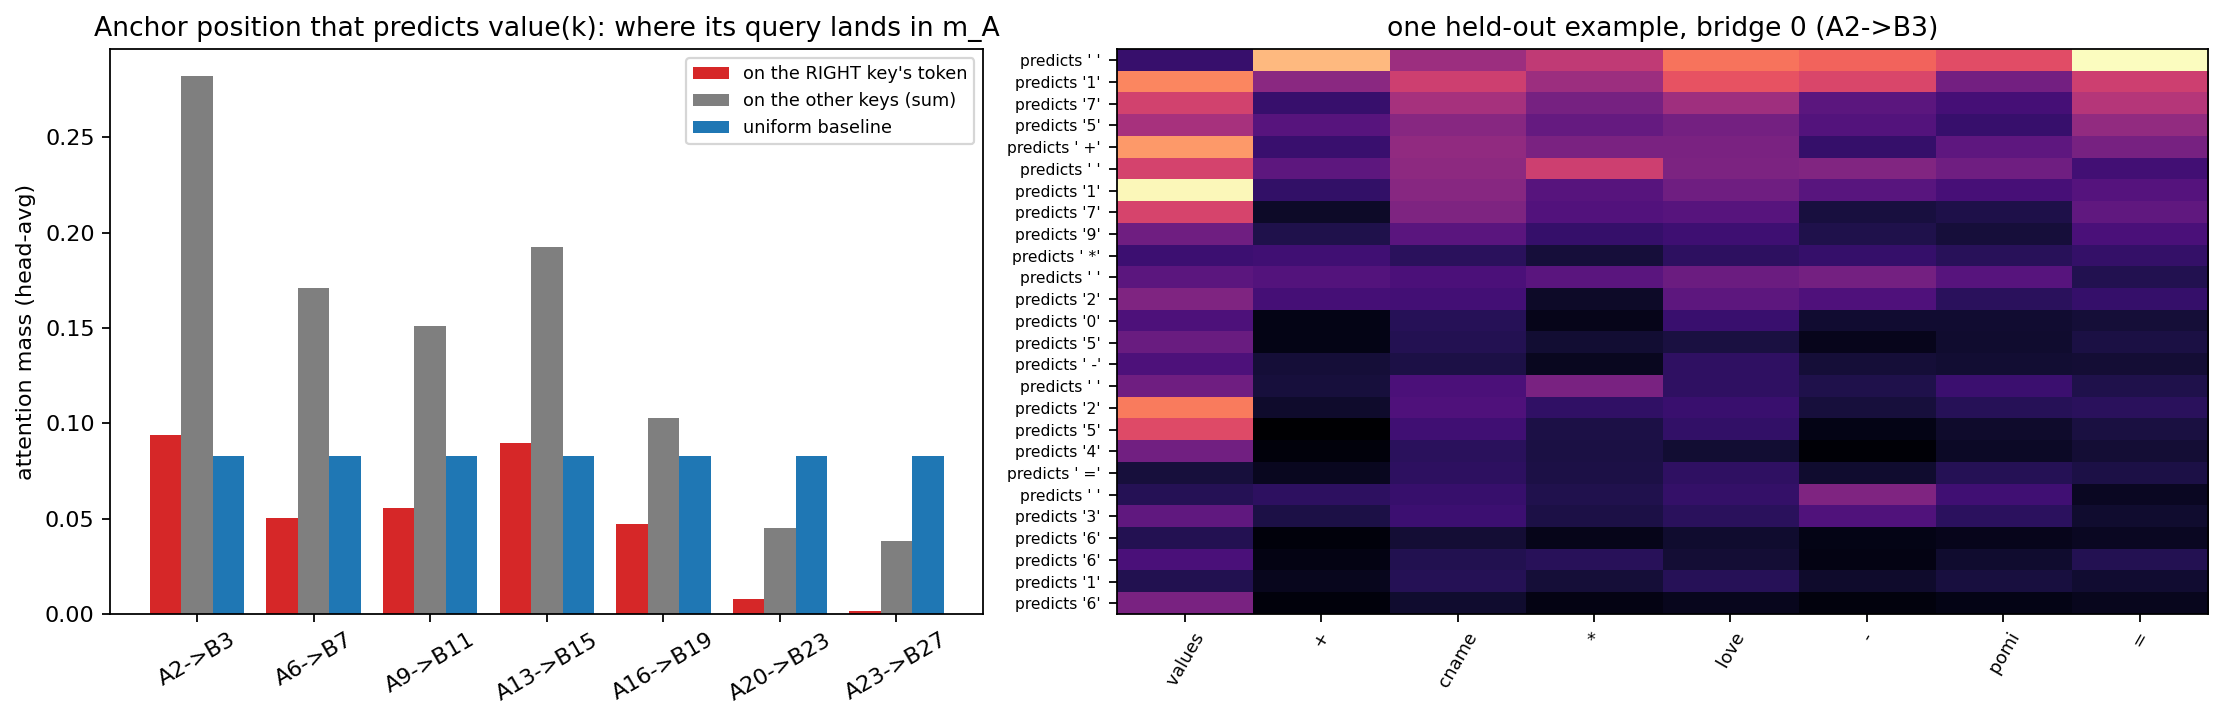

In [75]:
#@title Part 1 · open it up (C4): where does each bridge look when m_B writes a key's value?
A = R["attn"]; pl = np.array(A["per_layer"]); x = np.arange(len(pl))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
for o, (col, lab, c) in enumerate([(0, "on the RIGHT key's token", "#d62728"), (1, "on the other keys (sum)", "#7f7f7f"), (2, "uniform baseline", "#1f77b4")]):
    ax[0].bar(x + (o - 1) * 0.27, pl[:, col], 0.27, label=lab, color=c)
ax[0].set_xticks(x, [f"A{a}->B{b}" for a, b in zip(A["LA"], A["LB"])], rotation=30); ax[0].set_ylabel("attention mass (head-avg)")
ax[0].set_title("Anchor position that predicts value(k): where its query lands in m_A"); ax[0].legend(fontsize=8)
ex = A["example"]; li = int(pl[:, 0].argmax()); M = np.array(ex["attn"][li]); toks = ex["tokens"]
eq = toks.index(" =") if " =" in toks else ex["kpos"][-1] + 1
rows_, cols_ = list(range(eq, len(toks) - 1)), list(range(0, eq + 1))
ax[1].imshow(M[np.ix_(rows_, cols_)], aspect="auto", cmap="magma")
ax[1].set_xticks(range(len(cols_)), [toks[c] for c in cols_], rotation=60, fontsize=8)
ax[1].set_yticks(range(len(rows_)), [f"predicts {toks[r + 1]!r}" for r in rows_], fontsize=7)
ax[1].set_title(f"one held-out example, bridge {li} (A{A['LA'][li]}->B{A['LB'][li]})")
plt.tight_layout(); plt.savefig("/kaggle/working/calm/attn.png", dpi=110); plt.show()

## Part 1 verdict · CALM

| claim | paper | ours (unseen keys) | verdict |
|---|---|---|---|
| **C1** composition solves arithmetic over keys neither model can handle | KV-MATH: m_A 0.7, m_B 0.0, **CALM 84.3** | ×-set: 0 / 0 / **14.2**. ±-set: – / 0 / **27.7**. KV-SUBS **40.4** (×) and **34.3** (±) vs 0 for m_B | **direction reproduced, size not.** Both models stay frozen and a 75.7M-parameter bridge creates a skill neither had, from 0% to 14–28%. Still far below 84%. |
| **C2** the knowledge flows from m_A | (paper ablates m_A too) | vanilla m_A: **0.0%** on every unseen-key metric, but **100%** KV-SUBS on the 60 composition keys | **confirmed.** The bridge alone can memorise the keys it trained on; everything on unseen keys comes from m_A. |
| **C3** adapting m_B alone doesn't generalise | LoRA/FT baselines lose to CALM | m_B + LoRA (r=64) on the same D_C: **0.0%** unseen-key KV-SUBS and KV-MATH, **100%** KV-SUBS on the 60 seen keys | **confirmed.** It memorises and does not generalise; on unseen keys it writes values of seen keys (`288`, `287`). |
| **C4** the bridge looks at key k when writing value(k) | not claimed by the paper (our probe) | head-averaged attention on the right key is 0.002–0.094, about uniform (0.083) and **below the per-key share of the other keys** | **not supported** at head-average level. |

**Where the gap to 84% comes from, measured rather than guessed.** Two bottlenecks multiply:
- **Arithmetic ceiling.** m_B alone solves 11.8% (×) and 21% (±) of plain numeric expressions (paper's anchor: 73.7%). On the 60 *seen* keys, where retrieval is perfect (KV-SUBS 100%), composed KV-MATH is 28% (×) and **75.5% (±)**.
- **Retrieval generalisation.** Only 34–40% of unseen-key expressions get every value right. Per key that's about 75%, since expressions have 3–4 keys. The likely cause is our resize: the paper composes over 20% of **25K** keys (about 5,000 distinct keys to learn a general lookup from), ours over 20% of 300 = **60 keys**, for 1,500 steps.

**What broke:** (1) the first anchor/task pairing had an 11.8% arithmetic ceiling that would have capped any composition, so I added the ± variant with the same m_A and the same key split; (2) the attention recorder overflowed fp16 under autocast (`-1e9` mask) and now runs with autocast disabled; (3) two jobs on two GPUs wrote `results.json`, so saves now merge.

**Why C4 can fail while C1–C3 hold.** m_A is causal, so after it reads key k, every later position in its residual stream can carry k's value. The bridge does not need to look back at k's own token. A per-head analysis, or a causal ablation of m_A positions, is the next test. Neither was run.

# Part 2 · CIPHER: agents debating in embedding space
**Pham et al., ICLR 2024 · arXiv:2310.06272**

**Problem.** In multi-agent debate, copies of an LLM answer a question, read each other's answers and revise them. Each message is text, so at every step the model's full belief $p^{(t)}$ over 150k tokens is collapsed to **one sampled token**. The paper puts it this way: *"the token sampling step compresses the information of $p^{(t)}$ into a single token, discarding the information on all other tokens."*

**Method (Eq. 1–2).**
$$p^{(t)}=\mathrm{softmax}\big(\mathrm{logit}(\text{prompt},\text{res}^{(1:t-1)})/T\big),\qquad \text{NLD: } v^{(t)}\sim p^{(t)},\quad \text{CIPHER: } \mathrm{emb}^{(t)}=\sum_{v}p^{(t)}_v\,e_v$$
The weighted-average embedding goes straight back in as the next input, with no tokenizer involved. A message is the sequence of these vectors, and the other agent receives them **spliced into its prompt**. Generation stops when the vector's nearest vocabulary embedding is EOS. Only at the end is the message mapped to its nearest tokens so a human can read it.

```
 NLD    : logits ─softmax/T─► p ──sample──► one token id ──E[id]──► next input / message
 CIPHER : logits ─softmax/T─► p ──p·E────► a point between tokens ─► next input / message   (no sampling at all)
```
**What's special about it.** No training, no new parameters. It works for any agents that share an embedding table. It is deterministic given $T$, and $T$ sets how much of the uncertainty travels inside each vector. At $T\to0$ it reduces exactly to greedy text.

**Our run.** `cipher.py` shares every line between the two protocols **except `sample` vs `expectation`**, so the comparison is a single-variable ablation. Qwen2.5-1.5B-Instruct ×2 agents, 3 rounds, 300 GSM8K test questions (paper: LLaMA-2-70B and others, GSM8K/Arithmetic/MMLU; claims **+0.5 to 5.0 pp over NLD**). Power warning: with n=300 the standard error is about 2.5 pp, so a small real effect can be invisible. I report paired differences, not only means.

| claim | test |
|---|---|
| **C5** CIPHER ≥ NLD at matched temperature | final-round accuracy, paired over the same questions |
| **C6** the vectors carry information a token cannot | entropy of $p^{(t)}$ = nats per step that NLD throws away |
| **C7** messages stay human-readable | nearest-token read-out of real CIPHER messages |

In [33]:
%%writefile /kaggle/working/cipher/cipher.py
"""CIPHER (Pham et al. ICLR 2024, arXiv:2310.06272): LLM debate where messages are embeddings, not tokens.

Eq.1  p(t) = softmax{ logit(prompt, res(1:t-1)) / T }          <- same for both protocols
NLD : vocab(t) ~ p(t)  (sample ONE token)  -> "the token sampling step compresses the information of p(t) into a
      single token, discarding the information on all other tokens in the process."
CIPHER (Eq.2): emb(t) = sum_v p(t)_v * emb_v  -> the whole belief, as one point in embedding space, fed straight back
      in ("bypasses the tokenizer decoding step"); generation ends when the NEAREST-NEIGHBOUR token of emb(t) is EOS.
      The other agent receives these vectors spliced into its prompt. Only at the very end are they mapped back to
      the nearest tokens so a human (and our answer parser) can read them.
Here both protocols share every line of code except that one: `sample` vs `expectation`. Debate protocol follows the
paper (Du et al. 2023 style): 2 agents, 3 rounds, same model, per-agent temperatures. Model: Qwen2.5-1.5B-Instruct
(paper: LLaMA-2-70B etc.); data: GSM8K test (paper: GSM8K, Arithmetic, MMLU ...).
"""
import torch, json, re, os, sys, time, random, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, DynamicCache
from datasets import load_dataset
MID, W = "Qwen/Qwen2.5-1.5B-Instruct", "/kaggle/working/cipher"
tok = AutoTokenizer.from_pretrained(MID)
model = AutoModelForCausalLM.from_pretrained(MID, dtype=torch.float16).cuda().eval().requires_grad_(False)
E = model.get_input_embeddings().weight                     # (V, d) - the vocabulary's embedding table
E2 = (E.float() ** 2).sum(1)
STOP = torch.tensor([tok.convert_tokens_to_ids("<|im_end|>"), tok.convert_tokens_to_ids("<|endoftext|>")], device="cuda")
Q1 = ("Can you solve the following math problem? {q} Explain your reasoning. Your final answer should be a single "
      "numerical number, in the form \\boxed{{answer}}, at the end of your response.")
Q2 = ("These are the solutions to the problem from other agents: One agent solution: ```<<<OTHER>>>``` Using the reasoning "
      "from other agents as additional advice, can you give an updated answer? Examine your solution and that of other agents "
      "step by step. Put your final answer in the form \\boxed{answer} at the end of your response.")

def nearest(emb):                                            # nearest vocabulary embedding (L2) - the paper's read-out
    return (E2[None] - 2 * (emb.half() @ E.T).float()).argmin(-1)

def build(q, own=None, other=None):
    """Chat prompt as a sequence of EMBEDDINGS: text pieces are looked up in E, messages are spliced in as-is."""
    msgs = [{"role": "user", "content": Q1.format(q=q)}]
    if own is not None: msgs += [{"role": "assistant", "content": "<<<OWN>>>"}, {"role": "user", "content": Q2}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    out = []
    for part in re.split(r"(<<<OWN>>>|<<<OTHER>>>)", text):
        if part == "<<<OWN>>>": out.append(own)
        elif part == "<<<OTHER>>>": out.append(other)
        elif part: out.append(E[torch.tensor(tok(part, add_special_tokens=False).input_ids, device="cuda")])
    return torch.cat(out)

@torch.no_grad()
def respond(seqs, temps, mode, max_new=320, keep_top=0):
    B, d = len(seqs), E.shape[1]; L = max(s.shape[0] for s in seqs)
    x = torch.zeros(B, L, d, dtype=torch.float16, device="cuda"); am = torch.zeros(B, L, dtype=torch.long, device="cuda")
    for b, s in enumerate(seqs): x[b, L - len(s):] = s; am[b, L - len(s):] = 1          # left padding
    cache = DynamicCache()
    h = model.model(inputs_embeds=x, attention_mask=am, past_key_values=cache, use_cache=True).last_hidden_state[:, -1]
    T = torch.tensor(temps, device="cuda", dtype=torch.float32)[:, None]
    embs, ids, ents, tops = [[] for _ in range(B)], [[] for _ in range(B)], [[] for _ in range(B)], [[] for _ in range(B)]
    done = torch.zeros(B, dtype=torch.bool, device="cuda")
    for t in range(max_new):
        logits = model.lm_head(h).float()
        if mode == "greedy":
            nid = logits.argmax(-1); emb = E[nid]; p = None
        else:
            p = torch.softmax(logits / T, -1)                                            # Eq. 1
            if mode == "cipher":
                emb = (p.half() @ E); nid = nearest(emb)                                 # Eq. 2 : expectation, no sampling
            else:
                nid = torch.multinomial(p, 1)[:, 0]; emb = E[nid]                        # NLD : sample one token
        stop = torch.isin(nid, STOP) & ~done
        if p is not None:
            ent = -(p * p.clamp_min(1e-12).log()).sum(-1)                               # nats thrown away by sampling
            if keep_top: tp, ti = p.topk(keep_top, -1)
        for b in (~done & ~stop).nonzero()[:, 0].tolist():
            embs[b].append(emb[b]); ids[b].append(int(nid[b]))
            if p is not None: ents[b].append(float(ent[b]))
            if keep_top and p is not None: tops[b].append((ti[b].tolist(), [round(v, 4) for v in tp[b].tolist()]))
        done |= stop
        if done.all(): break
        am = torch.cat([am, (~done).long()[:, None]], 1)
        h = model.model(inputs_embeds=emb[:, None].half(), attention_mask=am, past_key_values=cache, use_cache=True).last_hidden_state[:, -1]
    return [(torch.stack(e) if e else E[STOP[:1]], i, en, tp) for e, i, en, tp in zip(embs, ids, ents, tops)]

def extract(text):
    m = re.findall(r"\\boxed\{([^{}]*)\}", text)
    s = m[-1] if m else (re.findall(r"-?[\d,]*\.?\d+", text) or [""])[-1]
    s = s.replace(",", "").replace("$", "").strip()
    try: return float(re.findall(r"-?\d*\.?\d+", s)[0])
    except Exception: return None

def debate(data, mode, temps, rounds=3, agents=2, bs=75, tag=""):
    n = len(data); msgs = [[None] * n for _ in range(agents)]; R = {"correct": [], "tokens": [], "entropy": []}; texts = None
    for r in range(rounds):
        new = [[None] * n for _ in range(agents)]; corr_r, tok_r, ent_r = [], [], []
        for a in range(agents):
            for s in range(0, n, bs):
                idx = list(range(s, min(n, s + bs)))
                seqs = [build(data[i]["q"]) if r == 0 else build(data[i]["q"], own=msgs[a][i], other=msgs[1 - a][i]) for i in idx]
                outs = respond(seqs, [temps[a]] * len(idx), mode, keep_top=5 if (s == 0 and a == 0) else 0)
                for i, o in zip(idx, outs): new[a][i] = o
            txt = [tok.decode(new[a][i][1]) for i in range(n)]                          # nearest-token read-out
            corr_r.append([extract(t) is not None and abs(extract(t) - data[i]["gold"]) < 1e-4 for i, t in enumerate(txt)])
            tok_r.append(sum(len(new[a][i][1]) for i in range(n)) / n)
            ent_r.append([sum(new[a][i][2]) / max(1, len(new[a][i][2])) for i in range(n)])
            if r == rounds - 1 and a == 0: texts = txt[:5]
            if r == 0 and a == 0: R["tops_r1"] = [(new[0][i][1], new[0][i][3]) for i in range(3)]
        msgs = [[o[0] for o in new[a]] for a in range(agents)]
        R["correct"].append(corr_r); R["tokens"].append(tok_r); R["entropy"].append(ent_r)
        print(f"[{tag}] round {r + 1}: acc per agent {[round(sum(c) / n, 4) for c in corr_r]}  msg-len {[round(t) for t in tok_r]}", flush=True)
    R["final_texts"] = texts; return R

if __name__ == "__main__":
    N = int(os.environ.get("N_Q", 300))
    ds = load_dataset("openai/gsm8k", "main", split="test").shuffle(seed=0).select(range(N))
    data = [dict(q=e["question"], gold=float(e["answer"].split("####")[-1].replace(",", "").strip())) for e in ds]
    CONFIGS = [("single_greedy", "greedy", (0.0,), 1, 1), ("nld_T0.7", "nld", (0.7, 0.7), 3, 2), ("cipher_T0.7", "cipher", (0.7, 0.7), 3, 2),
               ("nld_T0.3-1.0", "nld", (0.3, 1.0), 3, 2), ("cipher_T0.3-1.0", "cipher", (0.3, 1.0), 3, 2),
               ("cipher_T1.0", "cipher", (1.0, 1.0), 3, 2), ("nld_T0.7_seed1", "nld", (0.7, 0.7), 3, 2)]
    only = sys.argv[1:]
    for tag, mode, temps, rounds, agents in CONFIGS:
        f = f"{W}/{tag}.json"
        if os.path.exists(f) or (only and tag not in only): continue
        torch.manual_seed(1 if "seed1" in tag else 0); t0 = time.time()
        R = debate(data, mode, temps, rounds, agents, tag=tag); R["secs"] = time.time() - t0; R["temps"] = temps
        json.dump(R, open(f, "w")); print(f"[{tag}] saved in {R['secs']:.0f}s", flush=True)
    print("DONE", flush=True)


Writing /kaggle/working/cipher/cipher.py


In [77]:
#@title Part 2 results · CIPHER vs natural-language debate (NLD), paired on the same GSM8K questions
import glob, os
C = {os.path.basename(f)[:-5]: json.load(open(f)) for f in sorted(glob.glob("/kaggle/working/cipher/*.json"))}
def per_q(r, rnd=-1): return np.mean(np.array(r["correct"][rnd], dtype=float), 0)          # agent-mean correctness per question
rows = []
for k, r in C.items():
    rows.append({"run": k, "temps": r["temps"], "round-1 acc %": 100 * per_q(r, 0).mean(), "final acc %": 100 * per_q(r).mean(),
                 "agent-1 final %": 100 * np.mean(r["correct"][-1][0]), "msg len (tok)": np.mean(r["tokens"][-1]),
                 "entropy of p(t), nats/step": np.mean(r["entropy"][0]) if r["entropy"][0][0] else np.nan, "minutes": r["secs"] / 60})
display(pd.DataFrame(rows).set_index("run").round(2))
rng = np.random.default_rng(0)
def paired(a, b):
    d = per_q(C[a]) - per_q(C[b]); bs = [rng.choice(d, len(d)).mean() for _ in range(4000)]
    print(f"  {a:>16s} - {b:<16s}: {100 * d.mean():+5.2f} pp   95% bootstrap CI [{100 * np.percentile(bs, 2.5):+.2f}, {100 * np.percentile(bs, 97.5):+.2f}]")
print("Paired final-round differences (n = %d questions):" % len(per_q(next(iter(C.values())))))
for a, b in [("cipher_T0.7", "nld_T0.7"), ("cipher_T0.3-1.0", "nld_T0.3-1.0"), ("nld_T0.7_seed1", "nld_T0.7"), ("cipher_T0.7", "single_greedy")]:
    if a in C and b in C: paired(a, b)

,temps,round-1 acc %,final acc %,agent-1 final %,msg len (tok),"entropy of p(t), nats/step",minutes
run,,,,,,,
cipher_T0.3-1.0,"[0.3, 1.0]",58.50,46.33,52.00,228.08,0.31,27.50
cipher_T0.7,"[0.7, 0.7]",64.67,68.67,68.67,241.96,0.21,27.74
nld_T0.3-1.0,"[0.3, 1.0]",58.00,61.83,65.00,262.37,0.24,26.91
nld_T0.7,"[0.7, 0.7]",62.83,64.50,65.33,255.81,0.19,26.88
single_greedy,[0.0],64.33,64.33,64.33,249.98,0.00,2.22


Paired final-round differences (n = 300 questions):
       cipher_T0.7 - nld_T0.7        : +4.17 pp   95% bootstrap CI [-1.00, +9.50]
   cipher_T0.3-1.0 - nld_T0.3-1.0    : -15.50 pp   95% bootstrap CI [-20.83, -10.00]
       cipher_T0.7 - single_greedy   : +4.33 pp   95% bootstrap CI [-0.33, +9.33]


Nearest-token read-out of a real CIPHER message (C7), first 400 chars:
  To solve this problem, we need calculate how amount of money each girl has and then add them together.  1. Carmen has $100. 2. Samantha has $25 more than Carmen, so Samantha has $100 + $25 = $125. 3. Daisy has $50 more than Samantha, so Daisy has $125 + $50 = $175.  Now, let add up the amounts toCarmen + Samantha + Daisy = $100 + $125 + $175 = $400.  Therefore, the final answer is \boxed{400}. 

Positions where the vector is NOT just one token (top-1 prob < 0.9): the belief NLD would have thrown away
  step   0  read as 'To'            mix = 'To':0.42, 'Let':0.23, 'Sure':0.20, 'C':0.08
  step   1  read as ' solve'        mix = ' solve':0.68, ' find':0.27, ' determine':0.04, ' calculate':0.02
  step   2  read as ' this'         mix = ' this':0.82, ' the':0.18, ' how':0.00, ' for':0.00
  step   5  read as ' we'           mix = ' we':0.54, ' let':0.46, ' first':0.00, ' I':0.00
  step   6  read as ' need'         mix 

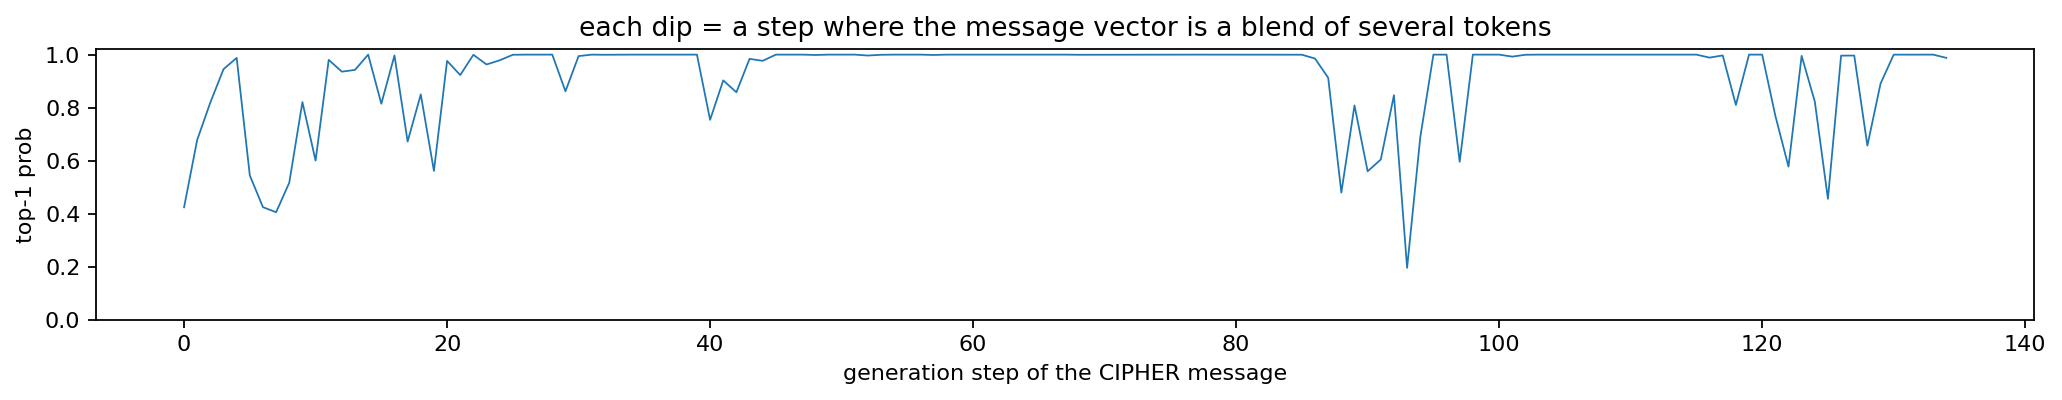

In [78]:
#@title Part 2 · open it up (C6, C7): what rides inside a CIPHER message that a token would drop?
from transformers import AutoTokenizer
qtok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
r = C.get("cipher_T0.7") or next(v for k, v in C.items() if k.startswith("cipher"))
ids, tops = r["tops_r1"][0]
H = [-sum(p * np.log(max(p, 1e-12)) for p in pr) for _, pr in tops]
print("Nearest-token read-out of a real CIPHER message (C7), first 400 chars:\n ", qtok.decode(ids)[:400].replace("\n", " "), "\n")
print("Positions where the vector is NOT just one token (top-1 prob < 0.9): the belief NLD would have thrown away")
shown = 0
for t, (ti, pr) in enumerate(tops):
    if pr[0] < 0.9 and shown < 14:
        shown += 1; print(f"  step {t:3d}  read as {qtok.decode([ids[t]])!r:14s}  mix = " + ", ".join(f"{qtok.decode([i])!r}:{p:.2f}" for i, p in zip(ti[:4], pr[:4])))
frac = np.mean([pr[0] < 0.9 for _, pr in tops])
print(f"\n{100 * frac:.1f}% of the {len(tops)} steps carry a real mixture (top-1 < 0.9).")
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.plot([pr[0] for _, pr in tops], lw=0.8); ax.set_ylim(0, 1.02)
ax.set_xlabel("generation step of the CIPHER message"); ax.set_ylabel("top-1 prob"); ax.set_title("each dip = a step where the message vector is a blend of several tokens")
plt.tight_layout(); plt.savefig("/kaggle/working/cipher/mixture.png", dpi=110); plt.show()

## Part 2 verdict · CIPHER

| claim | paper | ours (300 GSM8K test questions, paired) | verdict |
|---|---|---|---|
| **C5** CIPHER beats natural-language debate | +0.5 to 5.0 pp | **T=(0.7, 0.7):** 68.7 vs 64.5, **+4.2 pp, 95% CI [−1.0, +9.5]**. **T=(0.3, 1.0):** 46.3 vs 61.8, **−15.5 pp, CI [−20.8, −10.0]** | **not reproduced.** At matched T=0.7 the gain is in the paper's range but not significant. With one hot agent CIPHER is **significantly worse**. |
| **C6** the vectors carry information a token cannot | Fig. 1b | at T=0.7, **19%** of message steps are real mixtures (top-1 prob < 0.9); mean entropy 0.21 nats/step | **the extra information is real, but more information is not better.** See below. |
| **C7** messages remain human-readable | nearest-neighbour decoding | fluent text, with occasional dropped words (`"let's go the problem step by step"`) | **confirmed** |

**Two things this run exposes.**
1. **Equal temperatures make CIPHER agents identical.** There is no sampling, so two copies of one model at the same T produce the same vectors. The T=0.7 "debate" is one agent re-reading its own embedding-space answer. Against a single greedy agent it is +4.3 pp, CI [−0.3, +9.3]. This is why the paper gives each debater its own temperature.
2. **A high-temperature CIPHER agent poisons the debate.** Round by round, the T=1.0 agent goes **55 → 45 → 41%**, while its NLD twin at the same temperature goes 54 → 59 → 59%. By round 3 it also drags the T=0.3 agent down (65 → 52%). The mechanism: at high T the weighted average $\sum_v p_v e_v$ is a blend of many unrelated tokens, a point **between** tokens that the receiver was never trained on. Sampling at least always hands the reader a real token.

**Why this can differ from the paper:** the paper used 70B-scale models and tuned temperatures per model and dataset with Bayesian optimisation. A 1.5B model may be far less robust to off-manifold inputs. Its claimed effect (+0.5–5 pp) is also below what n=300 can resolve (CI width about 10 pp). **Not tested:** temperature tuning, more agents or rounds, other datasets, larger models.

# Part 3 · Coconut: one model reasoning inside its own hidden state
**Hao et al. (Meta) 2024 · arXiv:2412.06769**

**Problem.** Chain-of-thought pushes every reasoning step through the vocabulary. Each emitted token commits to one path, and most tokens exist only for fluency.

**Method (Sec. 3).** *"we use the last hidden state of the LLM as a representation of the reasoning state (termed 'continuous thought') ... we feed it back to the LLM as the subsequent input embedding directly in the continuous space."*
$$E_t=[e(x_1),\dots,e(x_i),\ h_i,\ h_{i+1},\dots,h_{t-1}]$$
```
 [ question tokens ... ] <bot>  h1 ─► h2 ─► h3 ─► h4 ─► h5 ─► h6  <eot>  ### Tom is a yumpus.
   language mode            └──── latent mode: each h is the last hidden state, fed back as the next input ────┘
```
**Training = a curriculum** (Fig. 2). Stage 0 is ordinary CoT. At stage $k$ *"the first k reasoning steps in the CoT are replaced with k×c continuous thoughts"*. The optimizer is reset at each stage, and the loss is masked on the question and the thoughts. With $n$ thoughts it takes $n{+}1$ sequential forward passes, and gradients flow back **through** every thought.

| stage | model input after the question |
|---|---|
| 0 | `step1 step2 step3 ### answer` |
| 1 | `<bot> h1 <eot> step2 step3 ### answer` |
| 2 | `<bot> h1 h2 <eot> step3 ### answer` |
| 6 | `<bot> h1 … h6 <eot> ### answer` |

**What's special about it.** A token commits to one node, but a continuous thought can hold **several candidate next nodes at once**. The paper reads this as the model running a **breadth-first search** in latent space and pruning as it goes (Fig. 5–7).

**Our run.** GPT-2 124M (paper's model), **ProsQA** (the paper's own data, pulled from the official repo), c=1, 6 stages, lr 1e-4, effective batch 128, all as in the paper. Resized: **9 epochs** instead of 50 (2 CoT + 1 per stage + 1 extra); 12.6 min/epoch on a T4. Paper's Table 1 on ProsQA: CoT **77.5%** (49.4 tokens), No-CoT 76.7%, Coconut **97.0%** (14.2 tokens).

| claim | test |
|---|---|
| **C8** Coconut beats CoT on ProsQA while generating far fewer tokens | stage-0 (CoT) vs stage-6 (Coconut) test accuracy + generated tokens |
| **C9** *(open it up)* decoding a thought with the LM head spreads probability over several frontier nodes, favouring ones that lead to the answer | top-k decode of $h_1..h_6$ against the ground-truth graph |

In [18]:
%%writefile /kaggle/working/coconut/coconut.py
"""Coconut (Hao et al. 2024, arXiv:2412.06769) on the paper's own ProsQA data with GPT-2 (124M), the paper's base model.

THE ONE IDEA (Sec. 3): "we use the last hidden state of the LLM as a representation of the reasoning state
(termed 'continuous thought') ... Rather than decoding this into a word token, we feed it back to the LLM as the
subsequent input embedding directly in the continuous space."   i.e.   E_t = [e(x_1..x_i), h_i, h_{i+1}, ..., h_{t-1}]

TRAINING (Sec. 3): "in the initial stage, the model is trained on regular CoT instances. In the subsequent stages,
at the k-th stage, the first k reasoning steps in the CoT are replaced with k x c continuous thoughts ... we also reset
the optimizer state when training stages switch. We insert <bot> and <eot> tokens ... mask the loss on questions and
latent thoughts."   ProsQA: c = 1, N = 6 stages, lr 1e-4, effective batch 128 (Sec. 4 / 5.1).

RESIZE vs paper: the paper trains 5 epochs/stage and stays in the last stage up to 50 epochs (~3.7 GPU-h on a T4 here).
We run E0 epochs of stage 0 (plain CoT = our CoT baseline), EK epochs for each of stages 1..6, EX extra at stage 6.
mode=nocot trains question -> '### answer' directly (the No-CoT baseline). Everything else is the paper's recipe.
"""
import json, math, os, random, sys, time, argparse
import torch, torch.nn.functional as F
from transformers import AutoTokenizer, GPT2LMHeadModel, DynamicCache

p = argparse.ArgumentParser()
p.add_argument("--mode", default="coconut")            # coconut | nocot
p.add_argument("--E0", type=int, default=3); p.add_argument("--EK", type=int, default=2); p.add_argument("--EX", type=int, default=1)
p.add_argument("--c", type=int, default=1); p.add_argument("--max_stage", type=int, default=6)
p.add_argument("--bs", type=int, default=32); p.add_argument("--accum", type=int, default=4); p.add_argument("--lr", type=float, default=1e-4)
p.add_argument("--out", default="/kaggle/working/coconut/run"); p.add_argument("--seed", type=int, default=0); p.add_argument("--smoke", type=int, default=0)
a, _ = p.parse_known_args()
os.makedirs(a.out, exist_ok=True); torch.manual_seed(a.seed); random.seed(a.seed)
LOG = open(f"{a.out}/log.txt", "a")
def log(*s):
    msg = time.strftime("%H:%M:%S ") + " ".join(map(str, s)); print(msg, flush=True); LOG.write(msg + "\n"); LOG.flush()

dev = "cuda"
tok = AutoTokenizer.from_pretrained("gpt2")
tok.add_special_tokens({"additional_special_tokens": ["<|start-latent|>", "<|end-latent|>", "<|latent|>"]})
BOT, EOT = tok.convert_tokens_to_ids("<|start-latent|>"), tok.convert_tokens_to_ids("<|end-latent|>")
EOS = tok.eos_token_id

def load_model():
    m = GPT2LMHeadModel.from_pretrained("gpt2", attn_implementation="sdpa")
    m.resize_token_embeddings(len(tok))
    with torch.no_grad():   # official repo initialises the new special tokens from an existing embedding
        w = m.transformer.wte.weight; w[BOT] = w[EOT] = w[-1] = w[tok.convert_tokens_to_ids("<<")]
    return m.to(dev)

D = "/kaggle/working/coconut/data"
def prep(split):
    out = []
    for e in json.load(open(f"{D}/prosqa_{split}.json")):
        out.append(dict(q=tok(e["question"] + "\n").input_ids, steps=[tok(s + "\n").input_ids for s in e["steps"]],
                        ans=tok("### " + e["answer"]).input_ids + [EOS], answer=e["answer"], raw=e))
    return out
TR, VA, TE = prep("train"), prep("valid"), prep("test")
if a.smoke: TR, VA, TE = TR[:256], VA[:64], TE[:64]

def n_latent(stage): return 0 if a.mode == "nocot" else stage * a.c      # "pad_latent_to_max": every sample gets k*c thoughts

def suffix(ex, stage):
    if a.mode == "nocot": return ex["ans"]
    rest = [t for s in ex["steps"][min(stage, len(ex["steps"])):] for t in s]   # first k steps removed (all, if chain is shorter)
    return ([EOT] if stage > 0 else []) + rest + ex["ans"]


Overwriting /kaggle/working/coconut/coconut.py


In [19]:
%%writefile -a /kaggle/working/coconut/coconut.py

# ---------------------------------------------------------------- the n+1-pass continuous-thought forward
def run(model, batch, stage, train=True, gen_tokens=0, keep_thoughts=False):
    """"We perform n + 1 forward passes when n latent thoughts are scheduled": pass 1 reads question+<bot> and yields
    thought 1 (= last hidden state at <bot>); passes 2..n each read ONE thought through the KV cache and yield the next;
    the final pass reads [h_n, <eot>, remaining language] and gives the loss. Gradients flow back through every thought.
    Questions are RIGHT-padded (pad slots masked out of the cache), so each sample's thoughts are gathered at its own
    last real token and carry its own position ids."""
    B, n = len(batch), n_latent(stage)
    pre = [ex["q"] + ([BOT] if n > 0 else []) for ex in batch]
    lens = torch.tensor([len(s) for s in pre], device=dev); Lp = int(lens.max())
    ids = torch.full((B, Lp), EOS, dtype=torch.long, device=dev); am = torch.zeros(B, Lp, dtype=torch.long, device=dev)
    for i, s in enumerate(pre): ids[i, :len(s)] = torch.tensor(s, device=dev); am[i, :len(s)] = 1
    wte, ar = model.transformer.wte, torch.arange(B, device=dev)
    cache = DynamicCache()
    o = model.transformer(inputs_embeds=wte(ids), attention_mask=am, position_ids=torch.arange(Lp, device=dev)[None].expand(B, -1),
                          past_key_values=cache, use_cache=True)
    h = o.last_hidden_state[ar, lens - 1][:, None]                          # hidden state at each sample's last real token
    last_logits = model.lm_head(h)
    nxt = lens[:, None]                                                     # next position id per sample
    thoughts = [h] if n > 0 else []
    for _ in range(n - 1):                                                  # passes 2..n: one continuous thought each
        am = torch.cat([am, am.new_ones(B, 1)], 1)
        o = model.transformer(inputs_embeds=h, attention_mask=am, position_ids=nxt, past_key_values=cache, use_cache=True)
        h = o.last_hidden_state; nxt = nxt + 1; thoughts.append(h)          # E_{t+1} = h_t : no tokenizer, no sampling
    if not train:
        return greedy(model, batch, stage, h if n > 0 else None, am, nxt, cache, last_logits, gen_tokens, thoughts if keep_thoughts else None)
    suf = [suffix(ex, stage) for ex in batch]; Ls = max(map(len, suf))
    sid = torch.full((B, Ls), EOS, dtype=torch.long); sm = torch.zeros(B, Ls, dtype=torch.long); lab = torch.full((B, Ls), -100, dtype=torch.long)
    for i, s in enumerate(suf):
        sid[i, :len(s)] = torch.tensor(s); sm[i, :len(s)] = 1; lab[i, :len(s)] = torch.tensor(s)
    lab[lab == EOT] = -100                                                   # "mask the loss on questions and latent thoughts"
    sid, sm, lab = sid.to(dev), sm.to(dev), lab.to(dev)
    emb = wte(sid)
    if n > 0: emb = torch.cat([h, emb], 1); sm = torch.cat([sm.new_ones(B, 1), sm], 1)   # final pass = [h_n, <eot>, rest]
    am = torch.cat([am, sm], 1)
    o = model.transformer(inputs_embeds=emb, attention_mask=am, position_ids=nxt + torch.arange(emb.shape[1], device=dev)[None],
                          past_key_values=cache, use_cache=True)
    hs = o.last_hidden_state[:, :Ls] if n > 0 else torch.cat([h, o.last_hidden_state[:, :Ls - 1]], 1)   # position t predicts suffix t
    keep = lab != -100                                                       # lm_head only where there is a label (memory)
    return F.cross_entropy(model.lm_head(hs[keep]).float(), lab[keep])

@torch.no_grad()
def greedy(model, batch, stage, h, am, nxt, cache, last_logits, T, thoughts):
    B = len(batch); wte = model.transformer.wte
    if h is not None:                                                      # feed h_n then <eot>, then decode language
        emb = torch.cat([h, wte(torch.full((B, 1), EOT, device=dev))], 1)
        am = torch.cat([am, am.new_ones(B, 2)], 1)
        o = model.transformer(inputs_embeds=emb, attention_mask=am, position_ids=nxt + torch.arange(2, device=dev)[None], past_key_values=cache, use_cache=True)
        logits = model.lm_head(o.last_hidden_state[:, -1:]); nxt = nxt + 2
    else:
        logits = last_logits
    out, done = [], torch.zeros(B, dtype=torch.bool, device=dev)
    for _ in range(T):
        t = logits[:, -1].argmax(-1); t = torch.where(done, torch.full_like(t, EOS), t); out.append(t); done |= t == EOS
        if done.all(): break
        am = torch.cat([am, am.new_ones(B, 1)], 1)
        o = model.transformer(inputs_embeds=wte(t[:, None]), attention_mask=am, position_ids=nxt, past_key_values=cache, use_cache=True)
        logits = model.lm_head(o.last_hidden_state); nxt = nxt + 1
    gen = torch.stack(out, 1).tolist()
    return (gen, thoughts) if thoughts is not None else gen

def answer_of(ids):
    s = tok.decode([t for t in ids if t != EOS]); return s.split("###")[-1].strip() if "###" in s else None

@torch.no_grad()
def evaluate(model, data, stage, bs=64):
    model.eval(); ok = 0; ntok = 0
    T = 16 if (stage >= a.max_stage or a.mode == "nocot") else 200
    with torch.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(data), bs):
            b = data[i:i + bs]
            for ex, g in zip(b, run(model, b, stage, train=False, gen_tokens=T)):
                ok += answer_of(g) == ex["answer"]; ntok += len([t for t in g if t != EOS])
    model.train(); return ok / len(data), ntok / len(data)


Appending to /kaggle/working/coconut/coconut.py


In [20]:
%%writefile -a /kaggle/working/coconut/coconut.py

# ---------------------------------------------------------------- the multi-stage curriculum
if __name__ == "__main__":
    model = load_model(); model.train()
    stages = [0] if a.mode == "nocot" else list(range(a.max_stage + 1))
    plan = [(s, (a.E0 + a.EK * a.max_stage + a.EX) if a.mode == "nocot" else (a.E0 if s == 0 else a.EK + (a.EX if s == a.max_stage else 0))) for s in stages]
    log("plan (stage, epochs):", plan, "| mode", a.mode)
    res = json.load(open(f"{a.out}/results.json")) if os.path.exists(f"{a.out}/results.json") else {}
    scaler = torch.amp.GradScaler()
    done_stages = [s for s in stages if os.path.exists(f"{a.out}/stage{s}.pt")]
    for stage, E in plan:
        ck = f"{a.out}/stage{stage}.pt"
        if done_stages and stage <= max(done_stages):                       # resume: skip finished stages, load the latest
            if stage == max(done_stages): model.load_state_dict(torch.load(ck, map_location=dev)); log("resumed from", ck)
            continue
        opt = torch.optim.AdamW(model.parameters(), lr=a.lr, weight_decay=0.01)      # optimizer RESET at every stage switch
        t0, step = time.time(), 0
        for ep in range(E):
            order = list(range(len(TR))); random.shuffle(order)
            for bi in range(len(order) // a.bs):
                b = [TR[j] for j in order[bi * a.bs:(bi + 1) * a.bs]]
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = run(model, b, stage) / a.accum
                scaler.scale(loss).backward()
                if (bi + 1) % a.accum == 0:
                    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
                    if step % 25 == 0: log(f"stage {stage} ep {ep} step {step} loss {loss.item() * a.accum:.4f} | {time.time() - t0:.0f}s")
            acc, nt = evaluate(model, VA, stage); log(f"== stage {stage} epoch {ep} VALID acc {acc:.4f}  gen-tokens {nt:.1f}")
            res[f"stage{stage}_ep{ep}_valid"] = acc
        torch.save(model.state_dict(), ck)
        if stage == 0 or stage == a.max_stage:
            acc, nt = evaluate(model, TE, stage); res[f"stage{stage}_test"] = acc; res[f"stage{stage}_test_tokens"] = nt
            log(f"#### stage {stage} TEST acc {acc:.4f}  gen-tokens {nt:.1f}")
        json.dump(res, open(f"{a.out}/results.json", "w"), indent=1)
        for s_old in range(1, stage):                                         # keep disk small: stage0 + the latest
            f = f"{a.out}/stage{s_old}.pt"
            if os.path.exists(f): os.remove(f)
    log("DONE")


Appending to /kaggle/working/coconut/coconut.py


In [28]:
#@title Launch Coconut curriculum on GPU0 (detached; logs to /kaggle/working/coconut/run/log.txt)
# Budget: 12.6 min/epoch on one T4 (7.3M tokens/epoch) -> 2 CoT epochs + 1 epoch per latent stage + 1 extra at stage 6 = 9 epochs.
import subprocess, os
def launch(cmd, log, gpu):
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTORCH_ALLOC_CONF="expandable_segments:True", TOKENIZERS_PARALLELISM="false")
    return subprocess.Popen(f"{cmd} > {log} 2>&1", shell=True, env=env, start_new_session=True)
os.makedirs("/kaggle/working/coconut/run", exist_ok=True)
P_coconut = launch("cd /kaggle/working/coconut && python coconut.py --mode coconut --bs 16 --accum 8 --E0 2 --EK 1 --EX 1",
                   "/kaggle/working/coconut/run/stdout.txt", gpu=0)
print("coconut pid", P_coconut.pid)

coconut pid 414


In [67]:
%%writefile /kaggle/working/coconut/probe.py
"""OPEN IT UP (C9): decode every continuous thought h_1..h_6 through GPT-2's LM head and read it against the true graph.
Paper Sec. 4: a thought is a superposition of "frontier nodes" = concepts reachable from the root in exactly t steps.
INSTRUMENT NOTE: the raw softmax is saturated - every thought puts ~1.0 on '###' (the model learned the answer marker
comes next), so every concept gets ~0. We therefore renormalise the logits over the graph's own concept tokens (first
BPE token of each concept name) and compare against the uniform floor = the frontier's share of all concepts.
For thought t: mass on frontier-t concepts vs the floor, and mean prob of frontier nodes that CAN reach the target vs not."""
import sys, json, collections; sys.argv = [sys.argv[0], "--out", "/kaggle/working/coconut/probe"]
from coconut import *
model = load_model(); model.load_state_dict(torch.load(f"/kaggle/working/coconut/run/stage{a.max_stage}.pt")); model.eval()
first = lambda s: tok(" " + s).input_ids[0]
S = [collections.defaultdict(list) for _ in range(a.max_stage)]; examples = []
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    for i in range(0, len(TE), 50):
        b = TE[i:i + 50]
        gens, th = run(model, b, a.max_stage, train=False, gen_tokens=16, keep_thoughts=True)
        Lg = [model.lm_head(h[:, 0]).float().cpu() for h in th]
        for j, ex in enumerate(b):
            g = ex["raw"]; syms = g["idx_to_symbol"]; kids, par = collections.defaultdict(list), collections.defaultdict(list)
            for u, v in g["edges"]: kids[u].append(v); par[v].append(u)
            dist, fr = {g["root"]: 0}, [g["root"]]
            while fr:
                nx = [v for u in fr for v in kids[u] if v not in dist]
                for v in nx: dist[v] = dist[[u for u in par[v] if u in dist][0]] + 1
                fr = list(dict.fromkeys(nx))
            good, fr = {g["target"]}, [g["target"]]
            while fr: fr = [u for v in fr for u in par[v] if u not in good]; good |= set(fr)
            concepts = [n for n in range(len(syms)) if n != g["root"] and syms[n][0].islower()]
            cid = sorted({first(syms[n]) for n in concepts})
            for t in range(a.max_stage):
                pr = dict(zip(cid, torch.softmax(Lg[t][j][cid], -1).tolist()))          # renormalised over concepts
                front = {first(syms[n]) for n in concepts if dist.get(n) == t + 1}
                if not front: continue
                S[t]["frontier"].append(sum(pr[x] for x in front)); S[t]["uniform"].append(len(front) / len(cid))
                gd = [pr[first(syms[n])] for n in concepts if dist.get(n) == t + 1 and n in good]
                bd = [pr[first(syms[n])] for n in concepts if dist.get(n) == t + 1 and n not in good]
                if gd and bd: S[t]["good"].append(sum(gd) / len(gd)); S[t]["bad"].append(sum(bd) / len(bd))
            if len(examples) < 4:
                ex_th = []
                for t in range(a.max_stage):
                    pr = torch.softmax(Lg[t][j][cid], -1); top = pr.topk(min(5, len(cid)))
                    ex_th.append([(tok.decode([cid[k]]), round(float(v), 3)) for v, k in zip(top.values, top.indices)])
                examples.append(dict(answer=ex["answer"], pred=answer_of(gens[j]), steps=g.get("steps", []), thoughts=ex_th,
                                     raw_top1=[tok.decode([int(Lg[t][j].argmax())]) for t in range(a.max_stage)]))
out = dict(per_thought=[{k: sum(v) / max(1, len(v)) for k, v in s.items()} | {"n": len(s["frontier"]), "n_pairs": len(s["good"])} for s in S], examples=examples)
json.dump(out, open("/kaggle/working/coconut/probe.json", "w"), indent=1)
for i, d in enumerate(out["per_thought"]): print(f"h{i + 1}", {k: round(v, 3) for k, v in d.items()})


Overwriting /kaggle/working/coconut/probe.py


                       method  test acc %  gen tokens  paper acc %  paper tokens
      CoT (stage 0, 2 epochs)        65.0        50.8         77.5          49.4
Coconut (stage 6, 6 thoughts)        80.0         8.2         97.0          14.2


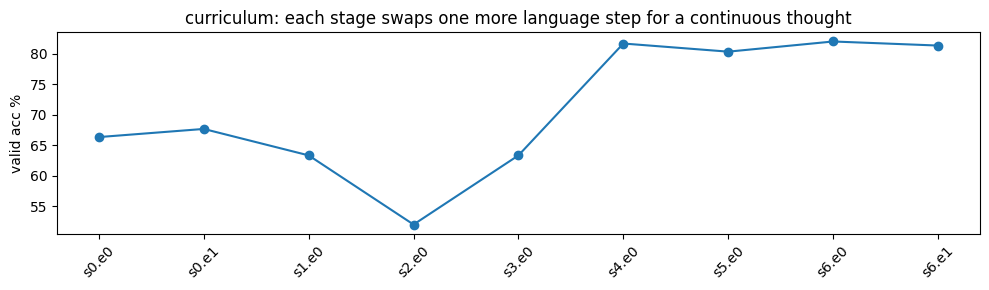

In [64]:
#@title Part 3 results · Coconut vs CoT on ProsQA (paper Table 1: CoT 77.5% / 49.4 tok, Coconut 97.0% / 14.2 tok)
K = json.load(open("/kaggle/working/coconut/run/results.json"))
print(pd.DataFrame([{"method": "CoT (stage 0, 2 epochs)", "test acc %": 100 * K.get("stage0_test", np.nan), "gen tokens": K.get("stage0_test_tokens"), "paper acc %": 77.5, "paper tokens": 49.4},
                    {"method": "Coconut (stage 6, 6 thoughts)", "test acc %": 100 * K.get("stage6_test", np.nan), "gen tokens": K.get("stage6_test_tokens"), "paper acc %": 97.0, "paper tokens": 14.2}]).round(1).to_string(index=False))
v = [(k, x) for k, x in K.items() if k.endswith("_valid")]
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(range(len(v)), [100 * x for _, x in v], "o-")
ax.set_xticks(range(len(v)), [k.replace("_valid", "").replace("stage", "s").replace("_ep", ".e") for k, _ in v], rotation=45)
ax.set_ylabel("valid acc %"); ax.set_title("curriculum: each stage swaps one more language step for a continuous thought"); plt.tight_layout(); plt.show()

Raw LM-head top-1 of every thought is ['###', '###', '###', '###', '###', '###'] -> saturated; below = softmax renormalised over the graph's concepts.

gold path: Sally is a scrompus. -> Every scrompus is a rempus. -> Every rempus is a sterpus.
answer 'Sally is a sterpus.'  model said 'Sally is a hilpus.'
   h1: ' w':0.219  ' r':0.193  ' l':0.141  ' y':0.141  ' j':0.067
   h2: ' h':0.305  ' y':0.21  ' ster':0.099  ' r':0.087  ' w':0.073
   h3: ' h':0.282  ' y':0.234  ' ster':0.097  ' r':0.089  ' w':0.071
   h4: ' h':0.282  ' y':0.234  ' ster':0.097  ' r':0.089  ' w':0.071
   h5: ' h':0.283  ' y':0.228  ' ster':0.098  ' r':0.089  ' w':0.072
   h6: ' h':0.281  ' y':0.226  ' ster':0.1  ' r':0.088  ' w':0.073

gold path: Bob is a storpus. -> Every storpus is a grimpus. -> Every grimpus is a jelpus. -> Every jelpus is a shumpus.
answer 'Bob is a shumpus.'  model said 'Bob is a shumpus.'
   h1: ' r':0.205  ' y':0.192  ' f':0.15  ' z':0.103  ' j':0.097
   h2: ' sh':0.873  ' y':0.069  ' r':0.0

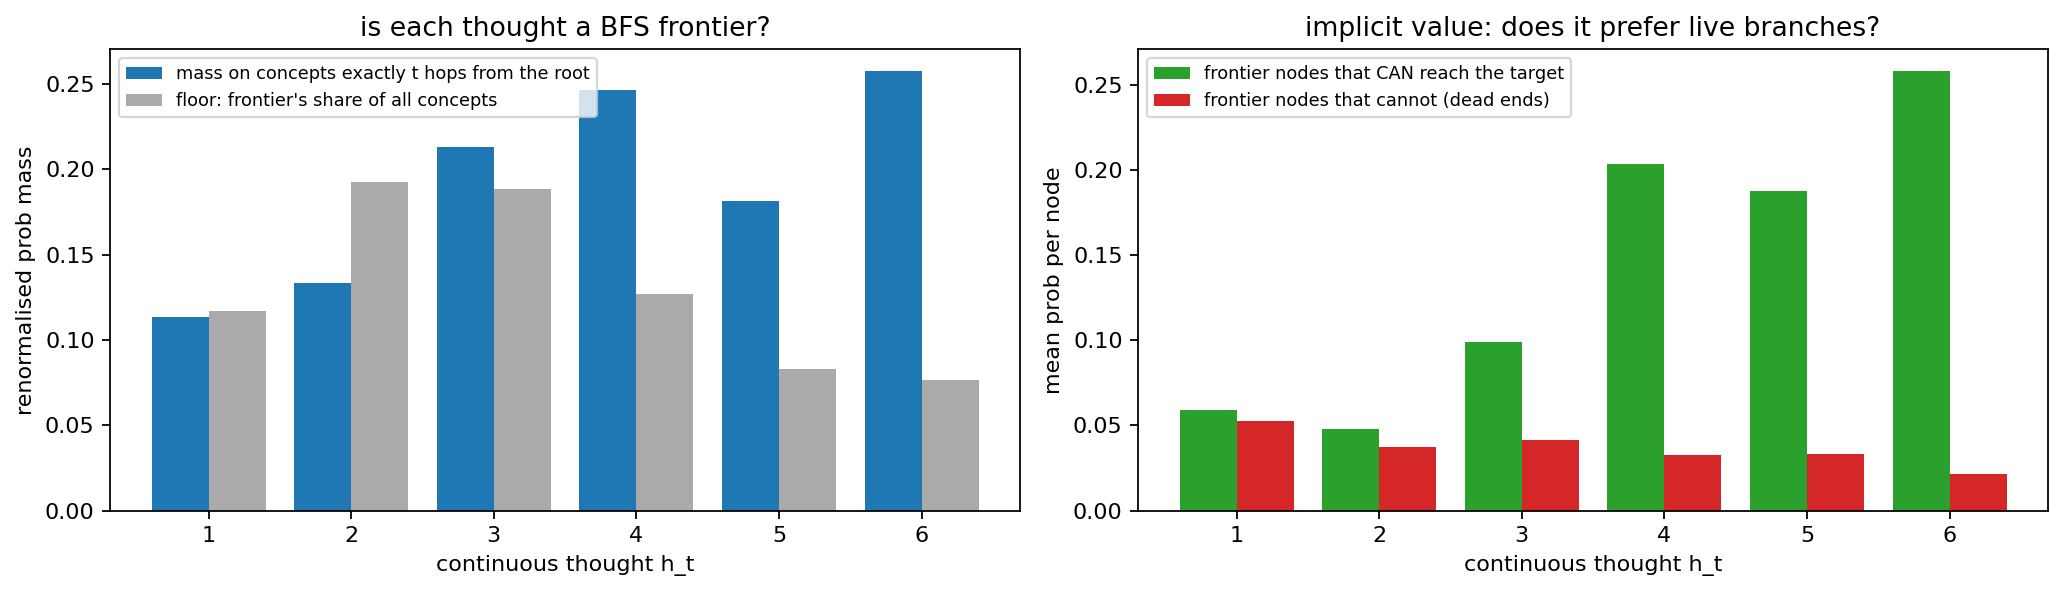

    frontier  uniform   good    bad    n  n_pairs
h1     0.113    0.117  0.059  0.052  500      288
h2     0.133    0.192  0.048  0.037  500      423
h3     0.213    0.188  0.099  0.041  500      440
h4     0.246    0.127  0.204  0.032  444      281
h5     0.181    0.083  0.188  0.033  254       78
h6     0.258    0.076  0.258  0.021   66       14


In [69]:
#@title Part 3 · open it up (C9): decode the continuous thoughts against the true graph
Pb = json.load(open("/kaggle/working/coconut/probe.json")); pt = Pb["per_thought"]
print("Raw LM-head top-1 of every thought is", Pb["examples"][0]["raw_top1"], "-> saturated; below = softmax renormalised over the graph's concepts.\n")
for e in Pb["examples"][:2]:
    print(f"gold path: {' -> '.join(e['steps'])}\nanswer {e['answer']!r}  model said {e['pred']!r}")
    for t, th in enumerate(e["thoughts"]): print(f"   h{t + 1}: " + "  ".join(f"{w!r}:{p}" for w, p in th))
    print()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); t = np.arange(1, len(pt) + 1)
ax[0].bar(t - 0.2, [d["frontier"] for d in pt], 0.4, label="mass on concepts exactly t hops from the root")
ax[0].bar(t + 0.2, [d["uniform"] for d in pt], 0.4, label="floor: frontier's share of all concepts", color="#aaaaaa")
ax[0].set_xlabel("continuous thought h_t"); ax[0].set_ylabel("renormalised prob mass"); ax[0].legend(fontsize=8); ax[0].set_title("is each thought a BFS frontier?")
ax[1].bar(t - 0.2, [d.get("good", 0) for d in pt], 0.4, label="frontier nodes that CAN reach the target", color="#2ca02c")
ax[1].bar(t + 0.2, [d.get("bad", 0) for d in pt], 0.4, label="frontier nodes that cannot (dead ends)", color="#d62728")
ax[1].set_xlabel("continuous thought h_t"); ax[1].set_ylabel("mean prob per node"); ax[1].legend(fontsize=8); ax[1].set_title("implicit value: does it prefer live branches?")
plt.tight_layout(); plt.savefig("/kaggle/working/coconut/probe.png", dpi=110); plt.show()
print(pd.DataFrame(pt, index=[f"h{i}" for i in t]).round(3).to_string())

## Part 3 verdict · Coconut

| claim | paper | ours | verdict |
|---|---|---|---|
| **C8** latent reasoning beats CoT on ProsQA with far fewer tokens | 97.0% vs 77.5%, 14.2 vs 49.4 tokens | **80.0% vs 65.0%** (n=500 test), **8.2 vs 50.8 tokens** | **reproduced in direction and size of the gap** (+15 pp vs +19.5 pp; 6.2× fewer tokens). Absolute accuracy is lower because we trained 9 of the paper's 50 epochs. One seed; SE is about 2 pp, so +15 pp is far outside noise. |
| **C9** a thought is a BFS frontier that favours live branches | Fig. 5–7 | **h1–h2: no** (frontier mass at or below the uniform floor). **h3–h6: yes**: frontier mass 1.1–3.4× the floor, and nodes that can still reach the target get **2.4–12× more probability** than dead ends (h4: 0.204 vs 0.032) | **partially reproduced.** The late thoughts behave like the paper's value-guided search; the first two don't concentrate on the frontier at all. |

**What broke, and the fixes (each one would have silently corrupted a number):**
1. GPT-2's *eager* attention keeps about six fp32 L×L tensors per layer, which ran out of memory at 600 tokens even at batch 16. Fix: SDPA. That required **right-padding** the questions and gathering each thought at the sample's own last token, because left padding creates fully-masked rows that can turn into NaN gradients.
2. `evaluate()` was first called without `no_grad`, so the prefix passes built a graph over 64×600 tokens and ran out of memory.
3. **The thought probe was saturated.** Through the LM head every thought puts ~1.0 on `###`, so each concept gets ~0 and the first reading was "no frontier signal anywhere", which is an instrument artifact. The fix renormalises over the graph's own concept tokens and reports the uniform floor next to every bar. The instrument is still coarse: several concept names share a first BPE token (`' w'`, `' r'`), and the floor is computed with the same collisions.

**Not tested:** the No-CoT, pause-token and "w/o curriculum" baselines (cut for time); more than one seed; the paper's full 50-epoch schedule; GSM8K and ProntoQA.

# Scoreboard: three ways to skip the tokenizer, on 2×T4

| paper | headline | paper's number | ours | verdict |
|---|---|---|---|---|
| **CALM** | two frozen LMs + cross-attention bridge gain a skill neither has | KV-arithmetic: 0.7 / 0.0 → **84.3** | 0 / 0 → **14.2** (paper's ops), **27.7** (± only); KV-subs on unseen keys 0 → **40.4** | **direction reproduced, size not.** The knowledge provably flows from m_A (C2 ✔), and m_B+LoRA can't generalise (C3 ✔). The gap splits into a measured arithmetic ceiling plus retrieval generalisation from only 60 composition keys. |
| **CIPHER** | debate in embedding space beats text debate | **+0.5 to 5.0 pp** | +4.2 pp (n.s.) at T=0.7, where the agents are identical; **−15.5 pp** (significant) at T=(0.3, 1.0) | **not reproduced.** Temperature decides the sign. Averaged embeddings at high T are off-manifold inputs that compound over rounds. |
| **Coconut** | latent reasoning beats CoT on planning-heavy ProsQA with far fewer tokens | 97.0 vs 77.5, 14.2 vs 49.4 tokens | **80.0 vs 65.0**, **8.2 vs 50.8 tokens** | **reproduced** (the gap and the 6× token cut) at 9 of 50 epochs. |

**Opening them up.**
- **CALM:** head-averaged, the bridge does *not* single out the key whose value it is writing. The lookup routes through other positions or specific heads.
- **CIPHER:** 1 in 5 message steps is a genuine blend of tokens. That extra information is exactly what hurts at high temperature.
- **Coconut:** the first two thoughts are not frontier-shaped. Thoughts 3–6 concentrate on the BFS frontier (up to 3.4× the uniform floor) and weight live branches up to 12× over dead ends, i.e. the paper's "implicit value".

**The common thread.** Skipping the tokenizer only helps when the receiver was **trained** to read the new channel. Coconut (the whole model trained) and CALM (the bridge trained) worked. CIPHER, the one with no training, has its receiver reading vectors it never saw. It broke exactly when those vectors moved far from real tokens.

**Setup:** Kaggle 2×T4 behind Colab, about 3 h 15 min wall-clock, every module in this notebook as a `%%writefile` cell. Artifacts (checkpoints, JSON results, figures) are in `/kaggle/working`, which is **wiped when the session ends**. The results live in this notebook's outputs, so save it (File → Save a copy).